# 07 — Corrected vertex-space linguistic encoding

## Purpose

This notebook asks a baseline question that is deliberately prior to the eigenmode-specific result:

> Which linguistic predictors produce stimulus-specific cortical effects in conventional vertexwise BOLD after the corrected nuisance preprocessing?

Primary predictors fixed before inspecting vertex-space results:

1. Sentence onset
2. Sentence shift
3. Token surprisal
4. Token curvature

The preprocessing below is copied from **06_nuisance_control_robustness**, which generated the saved corrected modal amplitudes. The branch point is therefore explicit:

\[
Y_{\rm corrected}
\rightarrow
\begin{cases}
\Phi^\top Y_{\rm corrected}\rightarrow A_k(t)^2 & \text{existing modal-energy analysis}\\
\text{vertexwise linguistic GLM} & \text{this notebook}
\end{cases}
\]

The primary vertex-space validation statistic is fixed prospectively as whole-cortex RMS of the signed group beta map. The complete signed beta maps are retained.

### Frozen corrected preprocessing

1. remove fMRIPrep non-steady-state volumes;
2. regress intercept + 6 motion + 6 motion derivatives + all retained combined-mask aCompCor + cosine drift;
3. vertexwise temporal standardization using NumPy `ddof=0`;
4. for QC only, project to the same fsaverage5 eigenmodes and reproduce the saved corrected modal amplitudes.

No GSR, continuous FD/DVARS, or motion-outlier spikes.

## 1. Imports, paths, eigenmodes, and frozen analysis settings

In [1]:
from pathlib import Path
import re, json
import numpy as np
import pandas as pd
import nibabel as nib

BASE = Path.home() / "eigenmode_fingerprints"
EMP = BASE / "data" / "empirical"
PANG = BASE / "pang_out"
EIG = BASE / "data" / "template_eigenmodes" / "fsaverage5"
NR = PANG / "nuisance_robustness"
CORR_A = NR / "corrected_modal_amplitudes"
OUT = NR / "vertex_space_linguistic_encoding"
OUT.mkdir(parents=True, exist_ok=True)

MIN_TRS = 100
K = 120

MOTION = ["trans_x","trans_y","trans_z","rot_x","rot_y","rot_z"]
MOTION_DERIV = [
    "trans_x_derivative1","trans_y_derivative1","trans_z_derivative1",
    "rot_x_derivative1","rot_y_derivative1","rot_z_derivative1",
]

phi_L = np.load(EIG / "phi_L.npy")[:, :K]
phi_R = np.load(EIG / "phi_R.npy")[:, :K]

print("phi_L:", phi_L.shape, "phi_R:", phi_R.shape)
print("Output:", OUT)

phi_L: (10242, 120) phi_R: (10242, 120)
Output: /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding


## 2. Reconstruct the same eligible BOLD/confounds grid as notebook 06

In [2]:
# ============================================================
# Helpers for locating files
# ============================================================

def parse_run(fname):
    m = re.search(r"_run-(\d+)_", fname)
    if m is None:
        raise ValueError(f"Cannot parse run number from {fname}")
    return int(m.group(1))


def find_confounds(sub_dir, sub, run):
    """
    Search both historical locations for the fMRIPrep
    confounds TSV.

    Return:
        Path if exactly one usable file is found
        None if none is found

    Raise if multiple distinct matches are found.
    """
    target = f"{sub}_task-lppEN_run-{run}_desc-confounds_timeseries.tsv"

    candidates = []

    for folder_name in ["func", "functional"]:
        folder = sub_dir / folder_name
        f = folder / target
        if f.exists():
            candidates.append(f)

    # Remove duplicate paths if any
    candidates = list(dict.fromkeys(candidates))

    if len(candidates) == 0:
        return None

    if len(candidates) > 1:
        raise RuntimeError(
            f"Multiple confound TSVs for {sub} run-{run}:\n"
            + "\n".join(str(x) for x in candidates)
        )

    return candidates[0]


# ============================================================
# Discover exactly one BOLD pair per subject/run
# ============================================================

rows = []

for sub_dir in sorted(EMP.glob("sub-*")):

    sub = sub_dir.name

    # Search both historical locations explicitly.
    # Some subjects (notably EN057) contain duplicate copies,
    # so resolve to ONE GIFTI per subject/run.
    candidates = []

    for folder_name in ["functional", "func"]:
        folder = sub_dir / folder_name

        if not folder.exists():
            continue

        candidates.extend(
            sorted(
                folder.glob(
                    f"{sub}_task-lppEN_run-*_hemi-L_space-fsaverage5_bold.func.gii"
                )
            )
        )

    # Group candidate files by scanner run
    by_run = {}

    for f in candidates:
        run = parse_run(f.name)
        by_run.setdefault(run, []).append(f)

    for run in sorted(by_run):

        files = by_run[run]

        # If duplicated across func/ and functional/, prefer
        # functional/ because that is where the main empirical
        # GIFTI tree resides. This choice should not matter if
        # files are identical; we audit duplicates below.
        preferred = [
            f for f in files
            if f.parent.name == "functional"
        ]

        if preferred:
            gii_L = preferred[0]
        else:
            gii_L = files[0]

        gii_R = gii_L.with_name(
            gii_L.name.replace("hemi-L", "hemi-R")
        )

        if not gii_R.exists():
            raise RuntimeError(
                f"Missing right-hemisphere pair:\n{gii_L}"
            )

        n_tr_L = len(nib.load(str(gii_L)).darrays)
        n_tr_R = len(nib.load(str(gii_R)).darrays)

        if n_tr_L != n_tr_R:
            raise RuntimeError(
                f"L/R TR mismatch for {sub} run-{run}: "
                f"L={n_tr_L}, R={n_tr_R}"
            )

        conf = find_confounds(
            sub_dir=sub_dir,
            sub=sub,
            run=run,
        )

        if conf is not None:
            n_conf = len(pd.read_csv(conf, sep="\t"))
            conf_match = (n_conf == n_tr_L)
        else:
            n_conf = np.nan
            conf_match = False

        rows.append({
            "subject": sub,
            "run": run,
            "n_tr": n_tr_L,
            "bold_L": gii_L,
            "bold_R": gii_R,
            "confounds": conf,
            "n_conf": n_conf,
            "confound_length_match": conf_match,
            "passes_min_tr": n_tr_L >= MIN_TRS,
            "n_bold_candidates": len(files),
        })


runs = (
    pd.DataFrame(rows)
    .sort_values(["subject", "run"])
    .reset_index(drop=True)
)

runs["eligible"] = (
    runs["passes_min_tr"]
    & runs["confounds"].notna()
    & runs["confound_length_match"]
)

print("Duplicate BOLD candidates resolved:")
print(
    runs.loc[
        runs["n_bold_candidates"] > 1,
        ["subject", "run", "n_tr", "n_bold_candidates", "bold_L"]
    ].to_string(index=False)
)

Duplicate BOLD candidates resolved:
  subject  run  n_tr  n_bold_candidates                                                                                                                                     bold_L
sub-EN057   15   286                  2 /home/whinzen/eigenmode_fingerprints/data/empirical/sub-EN057/functional/sub-EN057_task-lppEN_run-15_hemi-L_space-fsaverage5_bold.func.gii
sub-EN057   16   302                  2 /home/whinzen/eigenmode_fingerprints/data/empirical/sub-EN057/functional/sub-EN057_task-lppEN_run-16_hemi-L_space-fsaverage5_bold.func.gii
sub-EN057   17   344                  2 /home/whinzen/eigenmode_fingerprints/data/empirical/sub-EN057/functional/sub-EN057_task-lppEN_run-17_hemi-L_space-fsaverage5_bold.func.gii
sub-EN057   18   307                  2 /home/whinzen/eigenmode_fingerprints/data/empirical/sub-EN057/functional/sub-EN057_task-lppEN_run-18_hemi-L_space-fsaverage5_bold.func.gii
sub-EN057   19   269                  2 /home/whinzen/eigenmode_finge

## 3. Eligibility QC

The corrected modal-amplitude analysis had 440 eligible participant-runs / 49 participants. The linguistic grid later becomes 439 because EN059 run-17 lacks the sentence/token regressor set used here.

In [3]:
print("All discovered runs:", len(runs))
print("Eligible runs:", int(runs["eligible"].sum()))
print("Eligible participants:", runs.loc[runs["eligible"], "subject"].nunique())
print(runs.loc[runs["eligible"]].groupby("subject").size().value_counts().sort_index())
assert int(runs["eligible"].sum()) == 440
assert runs.loc[runs["eligible"], "subject"].nunique() == 49
eligible = runs.loc[runs["eligible"]].copy().reset_index(drop=True)

All discovered runs: 442
Eligible runs: 440
Eligible participants: 49
8     1
9    48
Name: count, dtype: int64


## 4. Exact preprocessing functions copied from notebook 06

In [4]:
def load_func_gii(path):
    g = nib.load(str(path))
    return np.column_stack(
        [da.data for da in g.darrays]
    ).astype(float)

def get_nonsteady_mask(confound_path):

    df = pd.read_csv(
        confound_path,
        sep="\t"
    )

    ns_cols = [
        c for c in df.columns
        if c.startswith(
            "non_steady_state_outlier"
        )
    ]

    if len(ns_cols) == 0:
        keep = np.ones(
            len(df),
            dtype=bool
        )
    else:
        flagged = (
            df[ns_cols]
            .fillna(0.0)
            .to_numpy()
            .sum(axis=1) > 0
        )

        keep = ~flagged

    return keep, ns_cols

def build_ordinary_nuisance_design(confound_path):

    confound_path = Path(confound_path)

    df = pd.read_csv(
        confound_path,
        sep="\t"
    )

    with open(
        confound_path.with_suffix(".json"),
        "r"
    ) as f:
        meta = json.load(f)

    motion_cols = MOTION + MOTION_DERIV

    acomp_cols = sorted(
        [
            c for c in df.columns
            if re.fullmatch(r"a_comp_cor_\d+", c)
            and meta.get(c, {}).get("Retained") is True
            and meta.get(c, {}).get("Method") == "aCompCor"
            and meta.get(c, {}).get("Mask") == "combined"
        ],
        key=lambda x: int(x.split("_")[-1])
    )

    cosine_cols = sorted([
        c for c in df.columns
        if c.startswith("cosine")
    ])

    selected = (
        motion_cols
        + acomp_cols
        + cosine_cols
    )

    C = (
        df[selected]
        .copy()
        .fillna(0.0)
    )

    C.insert(
        0,
        "intercept",
        1.0
    )

    X = C.to_numpy(float)

    assert (
        np.linalg.matrix_rank(X)
        == X.shape[1]
    )

    return X

def nuisance_residualize(Y, C):
    """
    Residualize vertices simultaneously.

    Parameters
    ----------
    Y : array, shape (vertices, time)
    C : array, shape (time, nuisance regressors)

    Returns
    -------
    residuals : array, shape (vertices, time)
    """

    # Solve:
    # Y.T = C @ B + residual
    #
    # B has shape nuisance x vertices

    B, _, _, _ = np.linalg.lstsq(
        C,
        Y.T,
        rcond=None
    )

    fitted = C @ B

    residuals = Y.T - fitted

    return residuals.T

def standardize(X):
    """
    Exact vertexwise temporal standardization used in batch_pang.py.

    Parameters
    ----------
    X : array, shape (vertices, time)

    Returns
    -------
    Z : array, shape (vertices, time)
        Each vertex mean-centered and scaled by its temporal SD.
        Uses NumPy's default ddof=0, matching the original pipeline.
    """
    mu = X.mean(axis=1, keepdims=True)
    sd = X.std(axis=1, keepdims=True)

    sd[sd == 0] = 1.0

    return (X - mu) / sd

## 5. One function for the exact corrected vertex signal

Input/output convention follows notebook 06: surface data are **vertices × time**.

This function stops immediately before the eigenmode projection. That matrix is the neural outcome for the new vertex-space GLM.

In [5]:
def corrected_vertex_bold(row, hemi):
    keep, _ = get_nonsteady_mask(row["confounds"])
    C = build_ordinary_nuisance_design(row["confounds"])
    assert C.shape[0] == len(keep)

    C_trim = C[keep, :]
    rank = np.linalg.matrix_rank(C_trim)
    if rank != C_trim.shape[1]:
        raise RuntimeError(
            f"{row['subject']} run-{int(row['run'])}: "
            f"rank deficiency {rank}/{C_trim.shape[1]}"
        )

    gii = row["bold_L"] if hemi == "L" else row["bold_R"]
    Y = load_func_gii(gii)
    assert Y.shape[1] == len(keep)

    Y_trim = Y[:, keep]
    Y_clean = nuisance_residualize(Y_trim, C_trim)
    Z_clean = standardize(Y_clean)

    return Z_clean, keep, C_trim

## 6. Mandatory reproduction of saved corrected modal amplitudes

This is the key provenance check. For selected runs/hemispheres, the newly generated corrected vertex matrix is projected as \(\Phi^	op Z\) and compared with the already-saved `corrected_modal_amplitudes`.

We require correlation > .999999999 and numerical agreement at tight tolerance before fitting vertexwise linguistic models.

In [6]:
qc_rows = []

# Representative runs: first, middle, last of eligible grid.
test_idx = sorted(set([0, len(eligible)//2, len(eligible)-1]))

for idx in test_idx:
    row = eligible.iloc[idx]
    subject = row["subject"]; run = int(row["run"])

    for hemi, phi in [("L", phi_L), ("R", phi_R)]:
        Z, keep, Ctrim = corrected_vertex_bold(row, hemi)
        A_re = phi.T @ Z

        afile = CORR_A / subject / f"run-{run}" / f"A_{hemi}.npy"
        A_saved = np.load(afile)

        assert A_re.shape == A_saved.shape
        diff = A_re - A_saved
        r = np.corrcoef(A_re.ravel(), A_saved.ravel())[0,1]

        qc_rows.append({
            "subject": subject, "run": run, "hemi": hemi,
            "shape": str(A_re.shape), "corr": r,
            "max_abs_diff": np.max(np.abs(diff)),
            "mean_abs_diff": np.mean(np.abs(diff)),
            "allclose_1e-10": np.allclose(A_re, A_saved, rtol=1e-10, atol=1e-10),
            "n_removed": int((~keep).sum()),
            "n_nuisance": Ctrim.shape[1],
        })

projection_qc = pd.DataFrame(qc_rows)
print(projection_qc.to_string(index=False))
assert (projection_qc["corr"] > .999999999).all()
assert projection_qc["allclose_1e-10"].all()
print("\nPREPROCESSING REPRODUCTION QC PASSED")

  subject  run hemi      shape  corr  max_abs_diff  mean_abs_diff  allclose_1e-10  n_removed  n_nuisance
sub-EN057   15    L (120, 284)   1.0           0.0            0.0            True          2          48
sub-EN057   15    R (120, 284)   1.0           0.0            0.0            True          2          48
sub-EN086   10    L (120, 265)   1.0           0.0            0.0            True          4          43
sub-EN086   10    R (120, 265)   1.0           0.0            0.0            True          4          43
sub-EN115   17    L (120, 369)   1.0           0.0            0.0            True          3          61
sub-EN115   17    R (120, 369)   1.0           0.0            0.0            True          3          61

PREPROCESSING REPRODUCTION QC PASSED


## 7. Exact linguistic regressor directories from notebook 06

In [7]:
SENT_ROOT = PANG / "regressors_sentence_controls_exact"
SENT_DIRS = {
    "sentence_onset": SENT_ROOT / "sentence_onset_hrf",
    "word_rate": SENT_ROOT / "word_rate_hrf",
    "content_density": SENT_ROOT / "content_density_hrf",
    "preceding_pause": SENT_ROOT / "preceding_pause_centered_hrf",
    "sentence_shift": SENT_ROOT / "sentence_shift_hrf",
    "acoustic_envelope": SENT_ROOT / "acoustic_envelope_hrf",
    "mean_log_f0": SENT_ROOT / "mean_log_f0_hrf",
    "pitch_reset": SENT_ROOT / "sentence_pitch_reset_hrf",
}
SENT_PREDICTORS = list(SENT_DIRS.keys())

TOKEN_ROOT = PANG / "regressors_qwen3_0p6b_continuous_centered"
TOKEN_WORD = TOKEN_ROOT / "word_rate_hrf_per_subject"
TOKEN_SURP = TOKEN_ROOT / "surprisal_sum_centered_hrf_per_subject"
TOKEN_CURV = TOKEN_ROOT / "curvature_centered_hrf_per_subject"

def reg_file(folder, subject, run):
    for name in [f"{subject}_run-{run}.npy", f"{subject}_run-{run:02d}.npy"]:
        f = folder / name
        if f.exists():
            return f
    return None

## 8. Build and audit the common 439-run linguistic grid

Regressors are constructed on the original full time grid and only then masked by the exact nonsteady-state mask, matching the corrected modal analysis.

In [8]:
ling_rows = []

for _, row in eligible.iterrows():
    subject=row["subject"]; run=int(row["run"])
    keep,_=get_nonsteady_mask(row["confounds"])
    T_full=len(keep)

    sent_files={p:reg_file(SENT_DIRS[p],subject,run) for p in SENT_PREDICTORS}
    token_files={
        "word_rate":reg_file(TOKEN_WORD,subject,run),
        "surprisal":reg_file(TOKEN_SURP,subject,run),
        "curvature":reg_file(TOKEN_CURV,subject,run),
    }

    sentence_ok=all(f is not None for f in sent_files.values())
    token_ok=all(f is not None for f in token_files.values())

    if sentence_ok:
        sentence_ok=all(len(np.asarray(np.load(f)).squeeze())==T_full for f in sent_files.values())
    if token_ok:
        token_ok=all(len(np.asarray(np.load(f)).squeeze())==T_full for f in token_files.values())

    ling_rows.append({
        "subject":subject,"run":run,"sentence_ok":sentence_ok,"token_ok":token_ok,
        "both_ok":sentence_ok and token_ok,"nTR_full":T_full,"nTR_final":int(keep.sum())
    })

ling_qc=pd.DataFrame(ling_rows)
print(ling_qc[["sentence_ok","token_ok","both_ok"]].value_counts())
common_grid=ling_qc.loc[ling_qc["both_ok"],["subject","run"]]
print("Common runs:",len(common_grid),"participants:",common_grid.subject.nunique())
print("Excluded:\n",ling_qc.loc[~ling_qc["both_ok"]].to_string(index=False))
assert len(common_grid)==439
assert common_grid.subject.nunique()==49

sentence_ok  token_ok  both_ok
True         True      True       439
False        False     False        1
Name: count, dtype: int64
Common runs: 439 participants: 49
Excluded:
   subject  run  sentence_ok  token_ok  both_ok  nTR_full  nTR_final
sub-EN059   17        False     False    False       372        370


In [9]:
# ============================================================
# REGRESSOR LOADERS NEEDED BY VERTEX FWL / NULL ANALYSIS
# Safe to run after Sections 1–9
# ============================================================

from pathlib import Path
import numpy as np

BASE = Path.home() / "eigenmode_fingerprints"

# ---------- exact sentence-level regressors ----------
SENT_ROOT = BASE / "pang_out" / "regressors_sentence_controls_exact"

SENT_DIRS = {
    "sentence_onset":   SENT_ROOT / "sentence_onset_hrf",
    "word_rate":        SENT_ROOT / "word_rate_hrf",
    "content_density":  SENT_ROOT / "content_density_hrf",
    "preceding_pause":  SENT_ROOT / "preceding_pause_centered_hrf",
    "sentence_shift":   SENT_ROOT / "sentence_shift_hrf",
    "acoustic_envelope":SENT_ROOT / "acoustic_envelope_hrf",
    "mean_log_f0":      SENT_ROOT / "mean_log_f0_hrf",
    "pitch_reset":      SENT_ROOT / "sentence_pitch_reset_hrf",
}

SENT_PREDICTORS = [
    "sentence_onset",
    "word_rate",
    "content_density",
    "preceding_pause",
    "sentence_shift",
    "acoustic_envelope",
    "mean_log_f0",
    "pitch_reset",
]


# ---------- exact token-level regressors ----------
TOKEN_ROOT = (
    BASE
    / "pang_out"
    / "regressors_qwen3_0p6b_continuous_centered"
)

TOKEN_DIRS = {
    "word_rate": (
        TOKEN_ROOT / "word_rate_hrf_per_subject"
    ),
    "surprisal": (
        TOKEN_ROOT / "surprisal_sum_centered_hrf_per_subject"
    ),
    "curvature": (
        TOKEN_ROOT / "curvature_centered_hrf_per_subject"
    ),
}


def _find_regressor_file(directory, subject, run):
    """
    Match the existing subject/run naming convention while allowing
    zero-padded or non-zero-padded run numbers.
    """
    run = int(run)

    candidates = [
        directory / f"{subject}_run-{run:02d}.npy",
        directory / f"{subject}_run-{run}.npy",
        directory / subject / f"run-{run:02d}.npy",
        directory / subject / f"run-{run}.npy",
    ]

    for p in candidates:
        if p.exists():
            return p

    # Fallback: use the actual existing filename rather than assuming
    # a particular run-number formatting convention.
    hits = list(directory.rglob(f"*{subject}*run-{run:02d}*.npy"))
    hits += list(directory.rglob(f"*{subject}*run-{run}*.npy"))

    # remove duplicates
    hits = list(dict.fromkeys(hits))

    if len(hits) != 1:
        raise FileNotFoundError(
            f"Could not uniquely locate regressor: "
            f"{directory}, {subject}, run {run}; hits={hits}"
        )

    return hits[0]


def _load_full_regressor(directory, subject, run):
    p = _find_regressor_file(directory, subject, run)
    x = np.asarray(np.load(p), dtype=float).squeeze()

    if x.ndim != 1:
        raise ValueError(
            f"Expected 1D regressor, got {x.shape}: {p}"
        )

    return x


def load_sentence_X(subject, run, keep):
    """
    Exact 8-predictor sentence design, followed by the exact
    nonsteady-state trimming mask.
    """
    cols = []

    for name in SENT_PREDICTORS:
        x = _load_full_regressor(
            SENT_DIRS[name],
            subject,
            run
        )

        if len(x) != len(keep):
            raise ValueError(
                f"{subject} run {run} {name}: "
                f"regressor length={len(x)}, keep={len(keep)}"
            )

        cols.append(x[keep])

    return np.column_stack(cols)


def load_token_X(subject, run, keep, predictor):
    """
    Exact token model:
        word rate + target predictor
    followed by the same nonsteady-state trimming.
    """
    if predictor not in ("surprisal", "curvature"):
        raise ValueError(predictor)

    wr = _load_full_regressor(
        TOKEN_DIRS["word_rate"],
        subject,
        run
    )

    x = _load_full_regressor(
        TOKEN_DIRS[predictor],
        subject,
        run
    )

    if len(wr) != len(keep) or len(x) != len(keep):
        raise ValueError(
            f"{subject} run {run} {predictor}: "
            f"wordrate={len(wr)}, predictor={len(x)}, "
            f"keep={len(keep)}"
        )

    return np.column_stack([
        wr[keep],
        x[keep],
    ])


# ---------- cheap smoke test ----------
_test = common_grid.iloc[0]
_s = _test["subject"]
_r = int(_test["run"])

_erow = eligible[
    (eligible["subject"] == _s)
    & (eligible["run"].astype(int) == _r)
].iloc[0]

_keep, _ = get_nonsteady_mask(_erow["confounds"])

_Xs = load_sentence_X(_s, _r, _keep)
_Xu = load_token_X(_s, _r, _keep, "surprisal")
_Xc = load_token_X(_s, _r, _keep, "curvature")

print("Regressor loader smoke test")
print("  subject/run:", _s, _r)
print("  retained TRs:", _keep.sum())
print("  sentence X:", _Xs.shape)
print("  surprisal X:", _Xu.shape)
print("  curvature X:", _Xc.shape)

assert _Xs.shape == (_keep.sum(), 8)
assert _Xu.shape == (_keep.sum(), 2)
assert _Xc.shape == (_keep.sum(), 2)

print("REGRESSOR LOADERS QC PASSED")

Regressor loader smoke test
  subject/run: sub-EN057 15
  retained TRs: 284
  sentence X: (284, 8)
  surprisal X: (284, 2)
  curvature X: (284, 2)
REGRESSOR LOADERS QC PASSED


In [12]:
# ============================================================
# SELF-CONTAINED SETUP FOR STREAMING FWL QC
# ============================================================

from pathlib import Path
import gc
import numpy as np
import pandas as pd

BASE = Path.home() / "eigenmode_fingerprints"

# Saved empirical vertex beta maps from the successful earlier run
BETA_RUN = (
    BASE
    / "pang_out"
    / "nuisance_robustness"
    / "vertex_space_linguistic_encoding"
    / "run_beta_maps"
)

assert BETA_RUN.exists(), f"Missing: {BETA_RUN}"

# Exact common 439-run linguistic grid
grid_set = {
    (str(r.subject), int(r.run))
    for r in common_grid.itertuples(index=False)
}

assert len(grid_set) == 439

print("Saved beta maps:", BETA_RUN)
print("Common grid reconstructed:", len(grid_set))


def residualize_against(Q, X):
    return X - Q @ (Q.T @ X)


def fwl_beta(Y, X, target_idx):
    """
    Y: time x vertices
    X: time x predictors, WITHOUT intercept
    target_idx: target predictor column

    Returns target beta map after residualizing target and Y
    against intercept + all other predictors.
    """
    nuisance_idx = [
        j for j in range(X.shape[1])
        if j != target_idx
    ]

    X0 = np.column_stack([
        np.ones(X.shape[0]),
        X[:, nuisance_idx]
    ])

    Q, _ = np.linalg.qr(X0, mode="reduced")

    # residualized target
    x = X[:, target_idx]
    xr = x - Q @ (Q.T @ x)

    denom = float(xr @ xr)
    if denom <= 1e-12:
        raise RuntimeError("Degenerate residualized predictor")

    # We do NOT need to construct/store residualized Y.
    # By FWL:
    # xr' (I - QQ') Y = xr'Y
    # because xr is already orthogonal to Q.
    beta = (xr @ Y) / denom

    return beta


fwl_qc = []
n_done = 0

for _, row in eligible.iterrows():

    subject = row["subject"]
    run = int(row["run"])

    if (subject, run) not in grid_set:
        continue

    keep, _ = get_nonsteady_mask(row["confounds"])

    # linguistic designs are tiny
    Xsent = load_sentence_X(
        subject, run, keep
    )
    Xsurp = load_token_X(
        subject, run, keep, "surprisal"
    )
    Xcurv = load_token_X(
        subject, run, keep, "curvature"
    )

    designs = {
        "sentence_onset": (
            Xsent,
            SENT_PREDICTORS.index("sentence_onset")
        ),
        "sentence_shift": (
            Xsent,
            SENT_PREDICTORS.index("sentence_shift")
        ),
        "token_surprisal": (
            Xsurp,
            1
        ),
        "token_curvature": (
            Xcurv,
            1
        ),
    }

    for hemi in ["L", "R"]:

        # exact corrected vertex signal from notebook 06 pipeline
        Z, keep2, _ = corrected_vertex_bold(
            row, hemi
        )

        assert np.array_equal(keep, keep2)

        # corrected_vertex_bold: vertices x time
        # transpose is a VIEW, not another persistent cache
        Y = Z.T

        for pred, (X, target_idx) in designs.items():

            b_fwl = fwl_beta(
                Y,
                X,
                target_idx
            )

            b_saved = np.load(
                BETA_RUN
                / subject
                / f"run-{run}"
                / f"{hemi}_{pred}.npy"
            )

            if b_saved.shape != b_fwl.shape:
                raise RuntimeError(
                    f"Shape mismatch {subject} run {run} "
                    f"{hemi} {pred}: "
                    f"{b_saved.shape} vs {b_fwl.shape}"
                )

            r = np.corrcoef(
                b_saved,
                b_fwl
            )[0, 1]

            maxdiff = float(
                np.max(
                    np.abs(b_saved - b_fwl)
                )
            )

            meandiff = float(
                np.mean(
                    np.abs(b_saved - b_fwl)
                )
            )

            fwl_qc.append({
                "subject": subject,
                "run": run,
                "hemisphere": hemi,
                "predictor": pred,
                "r": r,
                "max_abs_diff": maxdiff,
                "mean_abs_diff": meandiff,
            })

            # discard map immediately
            del b_fwl, b_saved

        n_done += 1

        # discard large vertex matrix immediately
        del Y, Z
        gc.collect()

        if n_done % 100 == 0:
            print(
                f"Processed {n_done}/878 "
                "hemisphere-runs"
            )


fwl_qc = pd.DataFrame(fwl_qc)

summary = (
    fwl_qc
    .groupby("predictor")
    .agg(
        n=("r", "size"),
        min_r=("r", "min"),
        mean_r=("r", "mean"),
        max_abs_diff=("max_abs_diff", "max"),
        mean_abs_diff=("mean_abs_diff", "mean"),
    )
)

print()
print(summary.to_string())

assert len(fwl_qc) == 878 * 4
assert (fwl_qc["r"] > 0.999999999).all()
assert (fwl_qc["max_abs_diff"] < 1e-8).all()

print()
print("VERTEX FWL REPRODUCTION QC PASSED")
print("878 hemisphere-runs × 4 predictors checked")
print("No vertex time-series matrices were cached.")

Saved beta maps: /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/run_beta_maps
Common grid reconstructed: 439
Processed 100/878 hemisphere-runs
Processed 200/878 hemisphere-runs
Processed 300/878 hemisphere-runs
Processed 400/878 hemisphere-runs
Processed 500/878 hemisphere-runs
Processed 600/878 hemisphere-runs
Processed 700/878 hemisphere-runs
Processed 800/878 hemisphere-runs

                   n  min_r  mean_r  max_abs_diff  mean_abs_diff
predictor                                                       
sentence_onset   878    1.0     1.0  7.716050e-15   2.297783e-16
sentence_shift   878    1.0     1.0  8.526513e-14   3.279577e-15
token_curvature  878    1.0     1.0  9.714451e-16   3.385913e-17
token_surprisal  878    1.0     1.0  2.720046e-15   4.027288e-17

VERTEX FWL REPRODUCTION QC PASSED
878 hemisphere-runs × 4 predictors checked
No vertex time-series matrices were cached.


In [15]:
# ============================================================
# VERTEX-SPACE STRUCTURED NULLS — 10-PERMUTATION QC
#
# Exact historical surrogate logic:
#   onset     : coherent circular shift of onset + pause
#   shift     : within-section permutation of shift magnitudes
#   surprisal : upstream token-value circular displacement
#   curvature : upstream token-value circular displacement
#
# Primary vertex statistic:
#   RMS of GROUP-MEAN SIGNED standardized beta* map
#
# Hierarchy:
#   run -> participant (within hemi) -> group
#   then concatenate L/R vertices -> RMS
#
# Streaming: no vertex time-series cache.
# ============================================================

from pathlib import Path
from collections import defaultdict
import gc
import time
import numpy as np
import pandas as pd
from scipy.stats import gamma as gamma_dist
from scipy.special import gamma as gamma_func

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

N_PERM_VERTEX = 10

SEED_ONSET = 20260915
SEED_SHIFT = 20260914
SEED_TOKEN = 20260915

MIN_SHIFT_TR = 20
MIN_SHIFT_FRAC = 0.10
TR = 2.0

BASE = Path.home() / "eigenmode_fingerprints"
PANG = BASE / "pang_out"

OUT_VERTEX_NULL = (
    PANG
    / "nuisance_robustness"
    / "vertex_space_linguistic_encoding"
    / "structured_null_qc"
)
OUT_VERTEX_NULL.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Reconstruct common grid locally
# ------------------------------------------------------------

grid_set = {
    (str(r.subject), int(r.run))
    for r in common_grid.itertuples(index=False)
}
assert len(grid_set) == 439

subjects_vertex = sorted({
    s for s, r in grid_set
})
assert len(subjects_vertex) == 49

sub_index = {
    s: i for i, s in enumerate(subjects_vertex)
}

# Number of runs contributed by each participant.
# Same count applies to both hemispheres.
nrun_subject = (
    pd.DataFrame(
        list(grid_set),
        columns=["subject", "run"]
    )
    .groupby("subject")
    .size()
    .to_dict()
)

print("Common runs:", len(grid_set))
print("Participants:", len(subjects_vertex))
print(
    "Runs/participant:",
    pd.Series(nrun_subject).value_counts().sort_index().to_dict()
)


# ============================================================
# 1. EXACT HISTORICAL SENTENCE-SHIFT EVENT GENERATOR
# ============================================================

SHIFT_EVENT_FILE = (
    PANG
    / "sentence_level_controls"
    / "sentence_shift_qwen_continuous.csv"
)

shift_events = pd.read_csv(SHIFT_EVENT_FILE)

if "stimulus_run" in shift_events.columns:
    shift_run_col = "stimulus_run"
elif "run_id" in shift_events.columns:
    shift_run_col = "run_id"
else:
    raise RuntimeError("Cannot identify shift stimulus-run column")

if "sentence_onset" in shift_events.columns:
    shift_onset_col = "sentence_onset"
elif "onset" in shift_events.columns:
    shift_onset_col = "onset"
else:
    raise RuntimeError("Cannot identify sentence-shift onset column")

if "sentence_shift" not in shift_events.columns:
    raise RuntimeError("sentence_shift absent from event table")

shift_events = shift_events.copy()

shift_events["shift_centered"] = (
    shift_events["sentence_shift"]
    - shift_events.groupby(shift_run_col)["sentence_shift"]
      .transform("mean")
)

shift_event_by_run = {}

for sr, d in shift_events.groupby(shift_run_col):

    d = d.sort_values(shift_onset_col)

    shift_event_by_run[int(sr)] = {
        "onsets":
            d[shift_onset_col].to_numpy(float),

        "weights":
            d["shift_centered"].to_numpy(float),
    }

assert sorted(shift_event_by_run) == list(range(1, 10))


def shift_hrf(tr=2.0, duration=32.0):

    t = np.arange(
        0.0, duration, tr,
        dtype=float
    )

    h = (
        gamma_dist.pdf(t, 6)
        - 0.5 * gamma_dist.pdf(t, 16)
    )

    m = np.max(np.abs(h))

    if m > 0:
        h = h / m

    return h


SHIFT_HRF = shift_hrf(TR)


def zscore_ddof1(x):

    x = np.asarray(x, float)

    sd = np.std(x, ddof=1)

    if not np.isfinite(sd) or sd == 0:
        return np.zeros_like(x)

    return (x - np.mean(x)) / sd


def build_shift_regressor(T, onsets, weights):

    impulses = np.zeros(T, dtype=float)

    for onset, weight in zip(onsets, weights):

        idx = int(
            np.round(float(onset) / TR)
        )

        if 0 <= idx < T:
            impulses[idx] += float(weight)

    reg = np.convolve(
        impulses,
        SHIFT_HRF,
        mode="full"
    )[:T]

    return zscore_ddof1(reg)


# ============================================================
# 2. IDENTIFY STIMULUS SECTION FOR EACH OF THE 439 RUNS
#
# Same stringent procedure as corrected shift null:
# match authoritative saved sentence_shift_hrf against all
# nine event-derived candidates.
# ============================================================

stimulus_map = {}
mapping_qc = []

for _, row in eligible.iterrows():

    subject = str(row["subject"])
    run = int(row["run"])

    if (subject, run) not in grid_set:
        continue

    keep, _ = get_nonsteady_mask(
        row["confounds"]
    )

    T_full = len(keep)

    saved_shift = _load_full_regressor(
        SENT_DIRS["sentence_shift"],
        subject,
        run
    )

    assert len(saved_shift) == T_full

    scores = {}

    for sr in range(1, 10):

        ev = shift_event_by_run[sr]

        candidate = build_shift_regressor(
            T_full,
            ev["onsets"],
            ev["weights"]
        )

        scores[sr] = float(
            np.corrcoef(
                saved_shift,
                candidate
            )[0, 1]
        )

    ranked = sorted(
        scores.items(),
        key=lambda z: z[1],
        reverse=True
    )

    best_sr, best_r = ranked[0]
    second_r = ranked[1][1]

    stimulus_map[(subject, run)] = best_sr

    mapping_qc.append({
        "subject": subject,
        "run": run,
        "stimulus_run": best_sr,
        "match_r": best_r,
        "margin": best_r - second_r,
        "T_full": T_full,
        "n_removed": int((~keep).sum()),
    })


mapping_qc = pd.DataFrame(mapping_qc)

print("\nStimulus mapping QC:")
print(
    mapping_qc[
        ["match_r", "margin"]
    ].describe().to_string()
)

print("\nStimulus-run counts:")
print(
    mapping_qc["stimulus_run"]
    .value_counts()
    .sort_index()
    .to_string()
)

assert len(stimulus_map) == 439
assert mapping_qc["match_r"].min() >= 0.999999

print("STIMULUS MAPPING QC PASSED")


# ============================================================
# 3. EXACT HISTORICAL TOKEN EVENT GENERATORS
# ============================================================

TRANS_CSV = (
    PANG
    / "word_transition_geometry_qwen3_0p6b_continuous"
    / "word_transition_geometry.csv"
)

SURP_CSV = (
    PANG
    / "token_surprisal_qwen_continuous"
    / "token_surprisal_qwen3_0p6b_continuous.csv"
)

trans = pd.read_csv(TRANS_CSV)
surp = pd.read_csv(SURP_CSV)

if "same_run" in trans.columns:
    trans = trans.loc[
        trans["same_run"] == 1
    ].copy()

trans["run_id"] = trans["run_id"].astype(int)
surp["run_id"] = surp["run_id"].astype(int)

TOKEN_INFO = {
    "token_surprisal": {
        "table": surp,
        "column": "surprisal_sum",
    },
    "token_curvature": {
        "table": trans,
        "column": "curvature",
    },
}

token_events = {
    p: {}
    for p in TOKEN_INFO
}

for pred, info in TOKEN_INFO.items():

    for sr in range(1, 10):

        d = (
            info["table"]
            .loc[
                info["table"]["run_id"] == sr
            ]
            .sort_values("onset")
            .copy()
        )

        on = d["onset"].to_numpy(float)
        val = d[info["column"]].to_numpy(float)

        good = (
            np.isfinite(on)
            & np.isfinite(val)
        )

        token_events[pred][sr] = {
            "onsets": on[good],
            "values": val[good],
        }


def token_hrf(tr=2.0, duration=32.0):

    t = np.arange(
        0.0, duration, tr,
        dtype=float
    )

    def gamma_pdf(x, a):

        x = np.asarray(x, float)
        out = np.zeros_like(x)

        m = x > 0
        xm = x[m]

        out[m] = (
            (xm ** (a - 1))
            * np.exp(-xm)
            / gamma_func(a)
        )

        return out

    h = (
        gamma_pdf(t, 6)
        - (1.0 / 6.0) * gamma_pdf(t, 16)
    )

    m = np.max(np.abs(h))

    if m > 0:
        h = h / m

    return h


TOKEN_HRF = token_hrf(TR)


def zscore_token(x):

    x = np.asarray(x, float)

    sd = np.nanstd(x)

    if not np.isfinite(sd) or sd == 0:
        return np.zeros_like(x)

    return (
        x - np.nanmean(x)
    ) / sd


def build_token_regressor(
    pred,
    stimulus_run,
    n_trs,
    lag=0
):

    ev = token_events[pred][stimulus_run]

    onsets = ev["onsets"]
    vals = ev["values"].copy()

    if lag != 0:
        vals = np.roll(
            vals,
            int(lag)
        )

    # Historical order:
    # center native values -> impulse -> HRF -> z-score
    vals = vals - np.mean(vals)

    x = np.zeros(
        n_trs,
        dtype=float
    )

    for onset, val in zip(
        onsets,
        vals
    ):

        if (
            not np.isfinite(onset)
            or not np.isfinite(val)
        ):
            continue

        idx = int(
            round(float(onset) / TR)
        )

        if 0 <= idx < n_trs:
            x[idx] += float(val)

    x = np.convolve(
        x,
        TOKEN_HRF,
        mode="full"
    )[:n_trs]

    return zscore_token(x)


# ============================================================
# 4. PRE-DRAW THE EXACT 10 HISTORICAL SURROGATES
# ============================================================

# ----- onset -----
#
# Historical generator:
# independent RNG(SEED + perm)
# one common lag per stimulus section;
# same lag applied to onset AND pause.

Tfull_by_section = defaultdict(list)

for _, q in mapping_qc.iterrows():
    Tfull_by_section[
        int(q["stimulus_run"])
    ].append(
        int(q["T_full"])
    )

onset_lags = []

for perm in range(N_PERM_VERTEX):

    rng = np.random.default_rng(
        SEED_ONSET + perm
    )

    dd = {}

    for sr in range(1, 10):

        Tmin = min(
            Tfull_by_section[sr]
        )

        poss = np.arange(
            MIN_SHIFT_TR,
            Tmin - MIN_SHIFT_TR
        )

        if len(poss) == 0:
            raise RuntimeError(
                f"No legal onset lag, section {sr}"
            )

        dd[sr] = int(
            rng.choice(poss)
        )

    onset_lags.append(dd)


# ----- sentence shift -----
#
# Historical generator:
# independent RNG(SEED + perm)
# permute centered sentence-shift weights within section.

shift_weights_perm = []

for perm in range(N_PERM_VERTEX):

    rng = np.random.default_rng(
        SEED_SHIFT + perm
    )

    dd = {}

    for sr in range(1, 10):

        dd[sr] = rng.permutation(
            shift_event_by_run[sr]["weights"]
        )

    shift_weights_perm.append(dd)


# ----- token predictors -----
#
# IMPORTANT:
# Historical token generator used ONE RNG stream and drew
# lags for ALL FIVE predictors in this order.
#
# We reproduce those unused draws too, so surprisal and
# curvature receive exactly their historical RNG sequence.

TOKEN_HIST_ORDER = [
    "Qwen surprisal",
    "Curvature",
    "Token shift",
    "AR trajectory residual",
    "Subspace exit",
]

token_length_lookup = {}

# lengths for the two predictors we need
for sr in range(1, 10):
    token_length_lookup[
        ("Qwen surprisal", sr)
    ] = len(
        token_events[
            "token_surprisal"
        ][sr]["values"]
    )

    token_length_lookup[
        ("Curvature", sr)
    ] = len(
        token_events[
            "token_curvature"
        ][sr]["values"]
    )

# lengths for the other three historical draws
OTHER_TOKEN_INFO = {
    "Token shift": "shift",
    "AR trajectory residual": "pred_error_ar",
    "Subspace exit": "pred_error_subspace",
}

for hist_pred, col in OTHER_TOKEN_INFO.items():

    for sr in range(1, 10):

        d = (
            trans.loc[
                trans["run_id"] == sr
            ]
            .sort_values("onset")
        )

        good = (
            np.isfinite(
                d["onset"].to_numpy(float)
            )
            & np.isfinite(
                d[col].to_numpy(float)
            )
        )

        token_length_lookup[
            (hist_pred, sr)
        ] = int(good.sum())


def draw_historical_token_lags(
    hist_pred,
    rng
):

    dd = {}

    for sr in range(1, 10):

        n = token_length_lookup[
            (hist_pred, sr)
        ]

        min_shift = max(
            1,
            int(
                np.floor(
                    MIN_SHIFT_FRAC * n
                )
            )
        )

        low = min_shift
        high = n - min_shift

        if high < low:
            raise RuntimeError(
                f"No legal token shift: "
                f"{hist_pred}, section {sr}"
            )

        dd[sr] = int(
            rng.integers(
                low,
                high + 1
            )
        )

    return dd


rng_token = np.random.default_rng(
    SEED_TOKEN
)

token_lags = []

for perm in range(N_PERM_VERTEX):

    this_perm = {}

    for hp in TOKEN_HIST_ORDER:

        d = draw_historical_token_lags(
            hp,
            rng_token
        )

        if hp == "Qwen surprisal":
            this_perm[
                "token_surprisal"
            ] = d

        elif hp == "Curvature":
            this_perm[
                "token_curvature"
            ] = d

    token_lags.append(
        this_perm
    )

print("\nExact historical surrogate draws prepared.")


# ============================================================
# 5. SMALL LINEAR-ALGEBRA HELPERS
# ============================================================

def residualize_vector(Q, x):

    return (
        x
        - Q @ (Q.T @ x)
    )


def standardized_single_beta(
    Y,
    x,
    fixed
):
    """
    Standardized partial coefficient map.

    Y is already vertexwise standardized by corrected_vertex_bold(),
    so beta* = beta * SD(x).
    """

    X0 = np.column_stack([
        np.ones(len(x)),
        fixed
    ])

    Q, _ = np.linalg.qr(
        X0,
        mode="reduced"
    )

    xr = x - Q @ (Q.T @ x)

    denom = float(xr @ xr)

    if (
        not np.isfinite(denom)
        or denom <= 1e-12
    ):
        raise RuntimeError(
            "Degenerate residualized predictor"
        )

    beta = (
        xr @ Y
    ) / denom

    sx = np.std(
        x,
        ddof=1
    )

    beta_star = beta * sx

    if not np.all(
        np.isfinite(beta_star)
    ):
        raise RuntimeError(
            "Non-finite beta* map"
        )

    return beta_star


def standardized_joint_onset_beta(
    Y,
    onset,
    pause,
    fixed6
):
    """
    Coherent onset+pause model.

    Both regressors are residualized jointly against the
    six fixed sentence covariates. Returns standardized
    ONSET coefficient map.

    Y is already standardized vertexwise.
    """

    X0 = np.column_stack([
        np.ones(len(onset)),
        fixed6
    ])

    Q, _ = np.linalg.qr(
        X0,
        mode="reduced"
    )

    G = np.column_stack([
        onset,
        pause
    ])

    Gr = (
        G
        - Q @ (Q.T @ G)
    )

    gram = Gr.T @ Gr

    B = np.linalg.solve(
        gram,
        Gr.T @ Y
    )

    beta_onset = B[0]

    sx = np.std(
        onset,
        ddof=1
    )

    beta_star = (
        beta_onset * sx
    )

    if not np.all(
        np.isfinite(beta_star)
    ):
        raise RuntimeError(
            "Non-finite onset beta* map"
        )

    return beta_star


# ============================================================
# 6. ACCUMULATORS
#
# Shape:
#   empirical: hemi x vertices
#   null:      perm x hemi x vertices
#
# We add each run already weighted by:
#   1 / participant run count / N participants
#
# Thus final accumulator IS the equal-participant group map.
# ============================================================

PREDICTORS_VERTEX = [
    "sentence_onset",
    "sentence_shift",
    "token_surprisal",
    "token_curvature",
]

group_emp = {
    p: {
        "L": None,
        "R": None,
    }
    for p in PREDICTORS_VERTEX
}

group_null = {
    p: {
        "L": None,
        "R": None,
    }
    for p in PREDICTORS_VERTEX
}

processed = 0
t_start = time.time()


# ============================================================
# 7. STREAM THROUGH ALL 878 HEMISPHERE-RUNS
# ============================================================

for _, row in eligible.iterrows():

    subject = str(
        row["subject"]
    )

    run = int(
        row["run"]
    )

    if (
        subject,
        run
    ) not in grid_set:
        continue

    keep, _ = get_nonsteady_mask(
        row["confounds"]
    )

    T_full = len(keep)

    sr = stimulus_map[
        (subject, run)
    ]

    # --------------------------------------------------------
    # Full saved sentence regressors
    # --------------------------------------------------------

    sent_full = {
        name:
            _load_full_regressor(
                SENT_DIRS[name],
                subject,
                run
            )
        for name in SENT_PREDICTORS
    }

    for name, x in sent_full.items():
        if len(x) != T_full:
            raise RuntimeError(
                f"{subject} run {run} "
                f"{name}: {len(x)} != {T_full}"
            )

    # corrected-grid empirical sentence design
    Xsent = np.column_stack([
        sent_full[n][keep]
        for n in SENT_PREDICTORS
    ])

    i_on = SENT_PREDICTORS.index(
        "sentence_onset"
    )

    i_pa = SENT_PREDICTORS.index(
        "preceding_pause"
    )

    i_sh = SENT_PREDICTORS.index(
        "sentence_shift"
    )

    # onset fixed six =
    # all sentence predictors except onset and pause
    onset_fixed_idx = [
        j
        for j in range(
            len(SENT_PREDICTORS)
        )
        if j not in (
            i_on,
            i_pa
        )
    ]

    # shift fixed seven =
    # all sentence predictors except shift
    shift_fixed_idx = [
        j
        for j in range(
            len(SENT_PREDICTORS)
        )
        if j != i_sh
    ]

    fixed_onset = Xsent[
        :,
        onset_fixed_idx
    ]

    fixed_shift = Xsent[
        :,
        shift_fixed_idx
    ]

    # --------------------------------------------------------
    # Token empirical designs
    # --------------------------------------------------------

    Xsurp = load_token_X(
        subject,
        run,
        keep,
        "surprisal"
    )

    Xcurv = load_token_X(
        subject,
        run,
        keep,
        "curvature"
    )

    wordrate_surp = Xsurp[:, [0]]
    wordrate_curv = Xcurv[:, [0]]

    # --------------------------------------------------------
    # Build all 10 surrogate regressors ONCE per run.
    # They are shared across hemispheres.
    # --------------------------------------------------------

    onset_null_x = []
    pause_null_x = []
    shift_null_x = []
    surp_null_x = []
    curv_null_x = []

    for perm in range(
        N_PERM_VERTEX
    ):

        # ---- onset + pause coherent full-grid shift ----
        lag = onset_lags[perm][sr]

        onset_null_x.append(
            np.roll(
                sent_full[
                    "sentence_onset"
                ],
                lag
            )[keep]
        )

        pause_null_x.append(
            np.roll(
                sent_full[
                    "preceding_pause"
                ],
                lag
            )[keep]
        )

        # ---- sentence-shift weight permutation ----
        ev = shift_event_by_run[sr]

        g_full = build_shift_regressor(
            T_full,
            ev["onsets"],
            shift_weights_perm[
                perm
            ][sr]
        )

        shift_null_x.append(
            g_full[keep]
        )

        # ---- token upstream circular displacement ----
        gs = build_token_regressor(
            "token_surprisal",
            sr,
            T_full,
            lag=token_lags[
                perm
            ][
                "token_surprisal"
            ][sr]
        )

        gc_ = build_token_regressor(
            "token_curvature",
            sr,
            T_full,
            lag=token_lags[
                perm
            ][
                "token_curvature"
            ][sr]
        )

        surp_null_x.append(
            gs[keep]
        )

        curv_null_x.append(
            gc_[keep]
        )

    # --------------------------------------------------------
    # Equal-participant weighting applied run-by-run
    # --------------------------------------------------------

    weight = (
        1.0
        / nrun_subject[subject]
        / len(subjects_vertex)
    )

    # --------------------------------------------------------
    # Hemispheres
    # --------------------------------------------------------

    for hemi in ["L", "R"]:

        Z, keep2, _ = corrected_vertex_bold(
            row,
            hemi
        )

        assert np.array_equal(
            keep,
            keep2
        )

        Y = Z.T

        V = Y.shape[1]

        # initialize accumulators lazily
        for pred in PREDICTORS_VERTEX:

            if group_emp[pred][hemi] is None:

                group_emp[pred][hemi] = (
                    np.zeros(
                        V,
                        dtype=np.float64
                    )
                )

                group_null[pred][hemi] = (
                    np.zeros(
                        (
                            N_PERM_VERTEX,
                            V
                        ),
                        dtype=np.float64
                    )
                )

        # ====================================================
        # EMPIRICAL beta* maps
        # ====================================================

        b = standardized_joint_onset_beta(
            Y,
            Xsent[:, i_on],
            Xsent[:, i_pa],
            fixed_onset
        )

        group_emp[
            "sentence_onset"
        ][hemi] += weight * b


        b = standardized_single_beta(
            Y,
            Xsent[:, i_sh],
            fixed_shift
        )

        group_emp[
            "sentence_shift"
        ][hemi] += weight * b


        b = standardized_single_beta(
            Y,
            Xsurp[:, 1],
            wordrate_surp
        )

        group_emp[
            "token_surprisal"
        ][hemi] += weight * b


        b = standardized_single_beta(
            Y,
            Xcurv[:, 1],
            wordrate_curv
        )

        group_emp[
            "token_curvature"
        ][hemi] += weight * b


        # ====================================================
        # NULL beta* maps
        # ====================================================

        for perm in range(
            N_PERM_VERTEX
        ):

            b = standardized_joint_onset_beta(
                Y,
                onset_null_x[perm],
                pause_null_x[perm],
                fixed_onset
            )

            group_null[
                "sentence_onset"
            ][hemi][perm] += weight * b


            b = standardized_single_beta(
                Y,
                shift_null_x[perm],
                fixed_shift
            )

            group_null[
                "sentence_shift"
            ][hemi][perm] += weight * b


            b = standardized_single_beta(
                Y,
                surp_null_x[perm],
                wordrate_surp
            )

            group_null[
                "token_surprisal"
            ][hemi][perm] += weight * b


            b = standardized_single_beta(
                Y,
                curv_null_x[perm],
                wordrate_curv
            )

            group_null[
                "token_curvature"
            ][hemi][perm] += weight * b

        del Y, Z
        gc.collect()

        processed += 1

        if processed % 100 == 0:

            elapsed = (
                time.time()
                - t_start
            )

            print(
                f"Processed {processed}/878 "
                f"hemisphere-runs | "
                f"{elapsed/60:.1f} min"
            )


assert processed == 878


# ============================================================
# 8. GROUP-MAP RMS
#
# Concatenate hemispheres only AFTER signed group averaging.
# ============================================================

def whole_cortex_rms(
    left,
    right
):

    x = np.concatenate([
        np.asarray(left),
        np.asarray(right)
    ])

    return float(
        np.sqrt(
            np.mean(
                x ** 2
            )
        )
    )


result_rows = []

for pred in PREDICTORS_VERTEX:

    empirical = whole_cortex_rms(
        group_emp[pred]["L"],
        group_emp[pred]["R"]
    )

    null = np.array([
        whole_cortex_rms(
            group_null[pred]["L"][p],
            group_null[pred]["R"][p]
        )
        for p in range(
            N_PERM_VERTEX
        )
    ])

    # QC-only +1 upper-tail p.
    # With 10 permutations minimum possible p = 1/11.
    p_qc = (
        1
        + np.sum(
            null >= empirical
        )
    ) / (
        N_PERM_VERTEX
        + 1
    )

    result_rows.append({
        "predictor":
            pred,

        "empirical_group_map_rms":
            empirical,

        "null_mean":
            float(
                np.mean(null)
            ),

        "null_sd":
            float(
                np.std(
                    null,
                    ddof=1
                )
            ),

        "null_min":
            float(
                np.min(null)
            ),

        "null_max":
            float(
                np.max(null)
            ),

        "n_null_ge_empirical":
            int(
                np.sum(
                    null >= empirical
                )
            ),

        "p_QC_ONLY":
            float(p_qc),
    })


result_df = pd.DataFrame(
    result_rows
)

print()
print("=" * 90)
print("VERTEX STRUCTURED-NULL 10-PERM QC")
print("=" * 90)
print(
    result_df.to_string(
        index=False
    )
)


# ============================================================
# 9. SAVE QC OUTPUTS
# ============================================================

result_df.to_csv(
    OUT_VERTEX_NULL
    / "vertex_structured_null_10perm_summary.csv",
    index=False
)

mapping_qc.to_csv(
    OUT_VERTEX_NULL
    / "stimulus_mapping_QC.csv",
    index=False
)

for pred in PREDICTORS_VERTEX:

    np.save(
        OUT_VERTEX_NULL
        / f"{pred}_empirical_group_beta_star_L.npy",
        group_emp[pred]["L"]
    )

    np.save(
        OUT_VERTEX_NULL
        / f"{pred}_empirical_group_beta_star_R.npy",
        group_emp[pred]["R"]
    )

    np.save(
        OUT_VERTEX_NULL
        / f"{pred}_null_group_beta_star_L_10perm.npy",
        group_null[pred]["L"]
    )

    np.save(
        OUT_VERTEX_NULL
        / f"{pred}_null_group_beta_star_R_10perm.npy",
        group_null[pred]["R"]
    )


print()
print("Saved QC outputs to:")
print(OUT_VERTEX_NULL)

print()
print(
    "10-PERM VERTEX NULL QC COMPLETE — "
    "DO NOT INTERPRET p-values inferentially."
)

Common runs: 439
Participants: 49
Runs/participant: {8: 2, 9: 47}

Stimulus mapping QC:
            match_r      margin
count  4.390000e+02  439.000000
mean   1.000000e+00    0.817553
std    2.022811e-16    0.043226
min    1.000000e+00    0.776609
25%    1.000000e+00    0.783523
50%    1.000000e+00    0.810655
75%    1.000000e+00    0.824163
max    1.000000e+00    0.914086

Stimulus-run counts:
stimulus_run
1    49
2    49
3    49
4    49
5    48
6    49
7    49
8    49
9    48
STIMULUS MAPPING QC PASSED

Exact historical surrogate draws prepared.
Processed 100/878 hemisphere-runs | 1.5 min
Processed 200/878 hemisphere-runs | 3.1 min
Processed 300/878 hemisphere-runs | 4.6 min
Processed 400/878 hemisphere-runs | 6.2 min
Processed 500/878 hemisphere-runs | 7.8 min
Processed 600/878 hemisphere-runs | 9.4 min
Processed 700/878 hemisphere-runs | 11.0 min
Processed 800/878 hemisphere-runs | 12.6 min

VERTEX STRUCTURED-NULL 10-PERM QC
      predictor  empirical_group_map_rms  null_mean  null

In [16]:
# ============================================================
# CACHE EXACT NUISANCE-CORRECTED VERTEX DATA FOR SLURM NULL
#
# Uses the already validated corrected_vertex_bold() function.
# float32 is sufficient for storage; all null GLM calculations
# in the worker are promoted to float64.
# ============================================================

from pathlib import Path
import gc
import numpy as np
import pandas as pd

BASE = Path.home() / "eigenmode_fingerprints"

ROOT = (
    BASE
    / "pang_out"
    / "nuisance_robustness"
    / "vertex_space_linguistic_encoding"
)

CACHE = ROOT / "corrected_vertex_cache"
OUT10000 = ROOT / "structured_null_10000"

CACHE.mkdir(parents=True, exist_ok=True)
OUT10000.mkdir(parents=True, exist_ok=True)

grid_set = {
    (str(r.subject), int(r.run))
    for r in common_grid.itertuples(index=False)
}

assert len(grid_set) == 439
assert len(stimulus_map) == 439

rows = []
n_done = 0

for _, row in eligible.iterrows():

    subject = str(row["subject"])
    run = int(row["run"])

    if (subject, run) not in grid_set:
        continue

    keep, _ = get_nonsteady_mask(
        row["confounds"]
    )

    run_dir = (
        CACHE
        / subject
        / f"run-{run}"
    )
    run_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Save exact keep mask used in the validated analysis
    np.save(
        run_dir / "keep.npy",
        keep
    )

    for hemi in ["L", "R"]:

        Z, keep2, _ = corrected_vertex_bold(
            row,
            hemi
        )

        assert np.array_equal(
            keep,
            keep2
        )

        assert Z.shape[0] == 10242
        assert Z.shape[1] == keep.sum()
        assert np.all(np.isfinite(Z))

        np.save(
            run_dir / f"Z_{hemi}.npy",
            Z.astype(
                np.float32,
                copy=False
            )
        )

        del Z
        gc.collect()

    rows.append({
        "subject":
            subject,

        "run":
            run,

        "stimulus_run":
            int(
                stimulus_map[
                    (subject, run)
                ]
            ),

        "T_full":
            int(len(keep)),

        "T_corrected":
            int(keep.sum()),

        "n_removed":
            int((~keep).sum()),
    })

    n_done += 1

    if n_done % 50 == 0:
        print(
            f"Cached {n_done}/439 runs"
        )


manifest = (
    pd.DataFrame(rows)
    .sort_values(
        ["subject", "run"]
    )
    .reset_index(drop=True)
)

assert len(manifest) == 439
assert manifest["subject"].nunique() == 49

manifest.to_csv(
    OUT10000
    / "vertex_cache_manifest.csv",
    index=False
)

print()
print("CACHE COMPLETE")
print("Runs:", len(manifest))
print(
    "Participants:",
    manifest["subject"].nunique()
)
print(
    "Hemisphere files:",
    2 * len(manifest)
)
print(
    "Manifest:",
    OUT10000
    / "vertex_cache_manifest.csv"
)

Cached 50/439 runs
Cached 100/439 runs
Cached 150/439 runs
Cached 200/439 runs
Cached 250/439 runs
Cached 300/439 runs
Cached 350/439 runs
Cached 400/439 runs

CACHE COMPLETE
Runs: 439
Participants: 49
Hemisphere files: 878
Manifest: /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/structured_null_10000/vertex_cache_manifest.csv


In [14]:
# Verify the corrected vertex data are already standardized
row0 = eligible[
    [
        (str(r.subject), int(r.run)) in grid_set
        for r in eligible.itertuples()
    ]
].iloc[0]

Z0, keep0, _ = corrected_vertex_bold(
    row0, "L"
)

sd0 = np.std(
    Z0,
    axis=1,
    ddof=1
)

valid = sd0 > 1e-8

print("Vertices:", len(sd0))
print("Valid/nonzero vertices:", valid.sum())
print("Zero-variance vertices:", (~valid).sum())
print(
    "SD across valid vertices:",
    np.min(sd0[valid]),
    np.median(sd0[valid]),
    np.max(sd0[valid])
)

del Z0
gc.collect()

Vertices: 10242
Valid/nonzero vertices: 9354
Zero-variance vertices: 888
SD across valid vertices: 1.001765226440103 1.0017652264401045 1.0017652264401058


595

## 9. Vertexwise OLS

For each run and hemisphere we fit the same models as the corrected modal analysis, but with corrected standardized **vertex BOLD** as the outcome.

Sentence model:
`onset + word rate + content density + preceding pause + sentence shift + acoustic envelope + mean log-F0 + pitch reset`

Token models:
`word rate + surprisal`
and
`word rate + curvature`.

The beta maps remain signed.

In [ ]:
def fit_vertex_glm(Z, Xpred):
    # Z: vertices x time; Xpred: time x predictors
    Xpred=np.asarray(Xpred,float)
    X=np.column_stack([np.ones(Xpred.shape[0]),Xpred])
    good=np.all(np.isfinite(X),axis=1)
    B,*_=np.linalg.lstsq(X[good], Z[:,good].T, rcond=None)
    return B  # (intercept + predictors) x vertices

def load_sentence_X(subject,run,keep):
    arr=[]
    for p in SENT_PREDICTORS:
        f=reg_file(SENT_DIRS[p],subject,run)
        x=np.asarray(np.load(f),float).squeeze()
        assert len(x)==len(keep)
        arr.append(x[keep])
    return np.column_stack(arr)

def load_token_X(subject,run,keep,kind):
    fw=reg_file(TOKEN_WORD,subject,run)
    fp=reg_file(TOKEN_SURP if kind=="surprisal" else TOKEN_CURV,subject,run)
    w=np.asarray(np.load(fw),float).squeeze()
    x=np.asarray(np.load(fp),float).squeeze()
    assert len(w)==len(keep)==len(x)
    return np.column_stack([w[keep],x[keep]])

## 10. Run empirical vertexwise models

To keep storage manageable, save one beta map per run/hemisphere/predictor rather than corrected BOLD time series. This also preserves the exact run-level hierarchy for later participant aggregation.

This is the first computationally substantial cell.

In [ ]:
BETA_RUN = OUT / "run_beta_maps"
BETA_RUN.mkdir(parents=True,exist_ok=True)
emp_qc=[]

grid_set=set(map(tuple,common_grid[["subject","run"]].to_records(index=False)))

for count,(_,row) in enumerate(eligible.iterrows(),start=1):
    subject=row["subject"]; run=int(row["run"])
    if (subject,run) not in grid_set:
        continue

    keep,_=get_nonsteady_mask(row["confounds"])
    Xsent=load_sentence_X(subject,run,keep)
    Xsurp=load_token_X(subject,run,keep,"surprisal")
    Xcurv=load_token_X(subject,run,keep,"curvature")
    sent_index={p:i+1 for i,p in enumerate(SENT_PREDICTORS)}

    rout=BETA_RUN/subject/f"run-{run}"
    rout.mkdir(parents=True,exist_ok=True)

    for hemi in ["L","R"]:
        Z,keep2,Ctrim=corrected_vertex_bold(row,hemi)
        assert np.array_equal(keep,keep2)

        Bs=fit_vertex_glm(Z,Xsent)
        Bu=fit_vertex_glm(Z,Xsurp)
        Bc=fit_vertex_glm(Z,Xcurv)

        maps={
            "sentence_onset":Bs[sent_index["sentence_onset"]],
            "sentence_shift":Bs[sent_index["sentence_shift"]],
            "token_surprisal":Bu[2],
            "token_curvature":Bc[2],
        }
        for pred,b in maps.items():
            assert np.all(np.isfinite(b))
            np.save(rout/f"{hemi}_{pred}.npy",b)

        emp_qc.append({
            "subject":subject,"run":run,"hemisphere":hemi,
            "nTR":Z.shape[1],"n_vertices":Z.shape[0],
            "n_nuisance":Ctrim.shape[1],"status":"ok"
        })

    if count==1 or count%50==0 or count==len(eligible):
        print(f"[{count:3d}/{len(eligible)}] {subject} run-{run}")

emp_qc=pd.DataFrame(emp_qc)
emp_qc.to_csv(OUT/"empirical_vertex_glm_QC.csv",index=False)
print("\nHemisphere-runs:",len(emp_qc))
print("Participants:",emp_qc.subject.nunique())
assert len(emp_qc)==878

## 11. Hierarchical participant and group beta maps

Hierarchy is fixed to mirror the modal analysis: average runs within participant and hemisphere, then use equal participant weighting for group maps.

We keep hemispheres separate for storage and concatenate them only when computing the whole-cortex statistic.

In [ ]:
PREDICTORS=["sentence_onset","sentence_shift","token_surprisal","token_curvature"]
SUB_BETA=OUT/"participant_beta_maps"; GROUP_BETA=OUT/"group_beta_maps"
SUB_BETA.mkdir(exist_ok=True); GROUP_BETA.mkdir(exist_ok=True)

subjects=sorted(common_grid.subject.unique())
for pred in PREDICTORS:
    for hemi in ["L","R"]:
        group=[]
        for subject in subjects:
            runs_sub=sorted(common_grid.loc[common_grid.subject==subject,"run"].astype(int))
            maps=[np.load(BETA_RUN/subject/f"run-{r}"/f"{hemi}_{pred}.npy") for r in runs_sub]
            b=np.mean(np.stack(maps),axis=0)
            sdir=SUB_BETA/subject; sdir.mkdir(exist_ok=True)
            np.save(sdir/f"{hemi}_{pred}.npy",b)
            group.append(b)
        g=np.mean(np.stack(group),axis=0)
        np.save(GROUP_BETA/f"{hemi}_{pred}.npy",g)

print("Saved participant and group signed beta maps.")

## 12. Prospectively fixed primary vertex statistic

\[
T_{m RMS}=\sqrt{rac{1}{V}\sum_veta_v^2}.
\]

For the empirical statistic, concatenate the two hemisphere group maps and compute RMS. This is a **global magnitude** test, not a localization test.

No vertexwise cluster search is used to decide whether a predictor validates.

In [ ]:
def cortical_rms(bL,bR):
    x=np.concatenate([np.asarray(bL,float),np.asarray(bR,float)])
    x=x[np.isfinite(x)]
    return float(np.sqrt(np.mean(x*x)))

empirical_stats=[]
for pred in PREDICTORS:
    L=np.load(GROUP_BETA/f"L_{pred}.npy")
    R=np.load(GROUP_BETA/f"R_{pred}.npy")
    empirical_stats.append({"predictor":pred,"vertex_RMS":cortical_rms(L,R)})

empirical_stats=pd.DataFrame(empirical_stats)
print(empirical_stats.to_string(index=False))
empirical_stats.to_csv(OUT/"empirical_vertex_RMS.csv",index=False)

## 12b. Predictor-scaling QC

Raw beta RMS is only compared with the corresponding predictor's own surrogate null. This cell documents why sentence-shift raw betas are numerically much larger: the shift regressor has much smaller variance.

This is diagnostic only and does not change the prospectively fixed primary statistic.

In [ ]:
scale_rows = []
for _, row in eligible.iterrows():
    subject=row["subject"]; run=int(row["run"])
    if (subject,run) not in grid_set:
        continue
    keep,_=get_nonsteady_mask(row["confounds"])
    Xsent=load_sentence_X(subject,run,keep)
    Xsurp=load_token_X(subject,run,keep,"surprisal")
    Xcurv=load_token_X(subject,run,keep,"curvature")
    vals={
        "sentence_onset":Xsent[:,SENT_PREDICTORS.index("sentence_onset")],
        "sentence_shift":Xsent[:,SENT_PREDICTORS.index("sentence_shift")],
        "token_surprisal":Xsurp[:,1],
        "token_curvature":Xcurv[:,1],
    }
    for pred,x in vals.items():
        scale_rows.append({"subject":subject,"run":run,"predictor":pred,
                           "sd_x":np.std(x,ddof=0)})
scale_qc=pd.DataFrame(scale_rows)
print(scale_qc.groupby("predictor")["sd_x"].agg(["mean","median","min","max"]))

## 13. Locate the three audited corrected null generators

Rather than reimplementing their stimulus logic from memory, the next cells import the already-audited corrected scripts from `code/`. The first run is deliberately only **10 permutations**.

The neural outcome is changed from modal energy to corrected vertexwise BOLD; the surrogate linguistic construction itself must remain unchanged.

In [2]:
from pathlib import Path

BASE = Path.home() / "eigenmode_fingerprints"

NULL_SCRIPTS = {
    "onset": BASE / "code" / "coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py",
    "shift": BASE / "code" / "sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py",
    "token": BASE / "code" / "token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py",
}

for k, f in NULL_SCRIPTS.items():
    print(k, f, "EXISTS" if f.exists() else "MISSING")

assert all(f.exists() for f in NULL_SCRIPTS.values())

NULL_SCRIPTS = {
    "onset": BASE/"code"/"coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py",
    "shift": BASE/"code"/"sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py",
    "token": BASE/"code"/"token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py",
}
for k,f in NULL_SCRIPTS.items():
    print(k, f, "EXISTS" if f.exists() else "MISSING")
assert all(f.exists() for f in NULL_SCRIPTS.values())

onset /home/whinzen/eigenmode_fingerprints/code/coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py EXISTS
shift /home/whinzen/eigenmode_fingerprints/code/sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py EXISTS
token /home/whinzen/eigenmode_fingerprints/code/token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py EXISTS
onset /home/whinzen/eigenmode_fingerprints/code/coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py EXISTS
shift /home/whinzen/eigenmode_fingerprints/code/sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py EXISTS
token /home/whinzen/eigenmode_fingerprints/code/token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py EXISTS


## 14. Inspect generator interfaces before porting

Run this cell and paste its output if any of the scripts have materially different function names than expected. It prints only definitions/constants and avoids dumping the full scripts.

In [4]:
import ast

for label,path in NULL_SCRIPTS.items():
    tree=ast.parse(path.read_text())
    funcs=[n.name for n in tree.body if isinstance(n,(ast.FunctionDef,ast.AsyncFunctionDef))]
    assigns=[]
    for n in tree.body:
        if isinstance(n,(ast.Assign,ast.AnnAssign)):
            targets=n.targets if isinstance(n,ast.Assign) else [n.target]
            for t in targets:
                if isinstance(t,ast.Name) and (
                    "SEED" in t.id or "PERM" in t.id or "SHIFT" in t.id or
                    "HRF" in t.id or "TR"==t.id
                ):
                    assigns.append(t.id)
    print("\n",label,":",path.name)
    print("functions:", funcs)
    print("relevant constants:", sorted(set(assigns)))


 onset : coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py
functions: ['parse', 'loadA', 'resid', 'fit', 'aggregate', 'stats']
relevant constants: ['MIN_SHIFT_TR', 'N_PERM', 'SEED']

 shift : sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py
functions: ['canonical_hrf', 'zscore', 'find_regressor', 'find_confounds', 'get_nonsteady_keep_mask', 'build_shift_regressor', 'correlation', 'direct_fit', 'prepare_fwl', 'aggregate_group_profile', 'fit_permuted_shift', 'upper_tail_p']
relevant constants: ['HRF', 'N_PERM', 'SEED', 'SHIFT_INDEX', 'TR']

 token : token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py
functions: ['canonical_hrf', 'convolve_hrf', 'zscore_safe', 'build_impulse_regressor', 'parse_run_number', 'get_subject_run_mapping', 'find_left_func_file', 'get_n_trs', 'find_confounds_file', 'steady_state_keep_mask', 'load_energy', 'build_token_regressor', 'estimate_profile', 'mean_abs', 'rms', 'draw_lags_for_predictor', 'p_greater']
relevant constants: ['HRF', 'MI

## 15. Vertex-null inference contract

For every permutation \(b\), the complete hierarchy is:

\[
\text{surrogate stimulus}^{(b)}
\rightarrow
\beta_{i,v}^{(b)}
\rightarrow
\bar\beta_v^{(b)}
\rightarrow
T_{\mathrm{RMS}}^{(b)}.
\]

The group map is formed **before** RMS so that participant-inconsistent signed patterns cancel.

QC requirements before 10,000 permutations:

- exact 439-run / 49-participant grid;
- empirical unshuffled beta map reproduced by the null-code path;
- only the target linguistic regressor/bundle is altered;
- identical run → participant → group hierarchy;
- 10 permutations complete for all four predictors;
- finite null RMS values.

Final one-sided Monte-Carlo inference uses the +1 correction.

In [ ]:
N_PERM_QC = 10
N_PERM_FINAL = 10_000
VERTEX_NULL_SEED = 20260928

def p_upper_plus1(empirical, null):
    null=np.asarray(null,float)
    assert np.all(np.isfinite(null))
    return (1 + np.sum(null >= empirical)) / (len(null) + 1)

print("QC permutations:",N_PERM_QC)
print("Final permutations:",N_PERM_FINAL)

## 16. Stimulus-specific nulls — implementation gate — fixed before inference

The null construction is **not changed** merely because the neural outcome is now vertexwise BOLD.

- Sentence onset: coherent within-section circular displacement of sentence onset + preceding pause; other six sentence predictors fixed.
- Sentence shift: centered shift magnitudes reassigned among true sentence transitions within section; event locations fixed.
- Token surprisal / curvature: native finite token values circularly displaced across their original eligible token positions, historical minimum displacement; impulses remain at original token onsets; HRF is built on the full grid before the nonsteady mask.

The audited corrected generators are:
- `coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py`
- `sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py`
- `token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py`

**Next step:** port their regressor-generation functions verbatim into the following cells while replacing only the modal-energy outcome by the corrected vertex outcome above. Begin with 10 permutations and require empirical-map reproduction before 10,000 permutations.

## 17. Null-analysis QC gate

Do not proceed to 10,000 permutations until each null implementation passes:

1. exact 439-run / 49-participant grid;
2. empirical (unshuffled) vertex beta maps reproduced from the null code path;
3. same hierarchical run → participant → group aggregation;
4. only the linguistic regressor is altered by the surrogate;
5. `N_PERM = 10` end-to-end test completes and saves null RMS values.

The final inference uses the +1 correction:

\[
p=rac{1+\#(T_{m null}\geq T_{m empirical})}{N_{m perm}+1}.
\]

In [ ]:
N_PERM = 10
SEED = 20260928

## 18. Decision log

- Notebook renumbered to **07** by user.
- Corrected preprocessing copied from notebook 06 rather than reconstructed from memory.
- Original surface BOLD is the neural source; no vertex reconstruction from eigenmodes.
- Primary predictors fixed prospectively: onset, sentence shift, surprisal, curvature.
- Primary vertex validation statistic fixed prospectively: whole-cortex RMS of the signed group beta map.
- Signed maps retained.
- No post-hoc vertexwise cluster search for validation.
- Full null inference remains locked until empirical preprocessing/projection QC passes.

# Definitive structured-null vertex-space validation (10,000 permutations)

## Purpose and status
This section freezes the definitive provenance and results of the nuisance-corrected vertex-space validation. Treat it as the authoritative record for this analysis.

The analysis complements the modal-energy analysis by asking whether linguistic predictors produce reproducible conventional **signed vertex-space BOLD response patterns** after corrected preprocessing, before asking whether they modulate modal energy \(E_k(t)=A_k(t)^2\).

The prospectively fixed whole-cortex statistic was the RMS magnitude of the **group-mean signed standardized-beta map**:
\[
T_{\mathrm{vertex}}=\sqrt{\frac{1}{V}\sum_v\left(\frac{1}{N}\sum_i\beta^*_{iv}\right)^2}.
\]
Signed maps are averaged before RMS, so non-reproducible spatial/sign patterns cancel rather than contributing positively through participant-wise magnitudes.

## Corrected preprocessing provenance
The vertex time series are exactly those underlying the nuisance-corrected modal amplitudes generated in notebook 06. Frozen pipeline:
1. remove fMRIPrep `non_steady_state_outlier*` volumes;
2. regress intercept + six motion parameters + six temporal derivatives + all fMRIPrep-retained combined-mask aCompCor components + cosine drift/high-pass regressors;
3. temporally standardize each cortical vertex;
4. retain these standardized vertex time series (the eigenmode branch subsequently projects the same signals).

No global-signal regression, continuous FD/DVARS regressors, motion-outlier spike regressors, or nonsteady-state dummy regressors are included. Preprocessing-reproduction QC in this notebook showed exact agreement between projection of reconstructed corrected vertex time series and saved corrected modal amplitudes (correlation 1.0; maximum difference 0 in tested runs/hemispheres).

## Analysis grid, scaling, and hierarchy
The common authoritative linguistic+nuisance grid contains **439 participant-runs from 49 participants (878 hemisphere-runs)**. The sole otherwise nuisance-eligible run lacking sentence regressors is `sub-EN059 run-17`.

Sentence model: sentence onset, word rate, content density, preceding pause, sentence representational shift, acoustic envelope, mean log-F0, sentence pitch reset. Token models: intercept + word rate + token surprisal; intercept + word rate + token curvature.

Coefficients are standardized run-wise as
\[
\beta_v^*=\beta_v\,SD(x),
\]
where \(x\) is the target regressor after exact nonsteady-state trimming. Division by \(SD(Y_v)\) is unnecessary because valid cortical vertex time series were already temporally standardized. Each surrogate uses its own target-regressor SD after trimming.

Run-level signed \(\beta^*\) maps are averaged within participant/hemisphere and then across participants with equal participant weighting; left and right hemispheres are concatenated before whole-cortex RMS.

## Structured nulls
**Sentence onset:** sentence onset and preceding pause are circularly displaced together by the same lag within each stimulus section; the other six sentence predictors remain fixed. Shifted onset and pause are fitted jointly after residualization against intercept + six fixed predictors.

**Sentence shift:** shift magnitudes are reassigned among true sentence transitions within each stimulus section while the seven other sentence predictors remain fixed. Historical event construction and HRF are used on the full stimulus grid before exact nonsteady-state trimming. Acquisition-run → stimulus-section identity was recovered by matching the saved empirical shift regressor to nine event-derived candidates; all 439 matches had \(r=1\).

**Token surprisal/curvature:** native token values are circularly displaced over each predictor's original eligible token positions, with historical minimum displacement of 10% of the eligible sequence. Surrogate impulses are placed at original token onsets, HRF-convolved and standardized on the full grid, then trimmed. Word rate remains fixed. The historical RNG stream is preserved.

All surrogate mappings are shared across participants hearing the same stimulus material.

## Numerical and implementation QC
Memory-safe FWL was checked against saved full-OLS empirical vertex maps for all 878 hemisphere-runs and all four predictors: correlations exactly 1.0; maximum absolute differences \(<9\times10^{-14}\).

The optimized cluster worker was checked permutation-by-permutation against the notebook implementation for the first 10 structured-null realizations: all four predictors had maximum absolute group-map differences \(<10^{-12}\), `allclose=True`.

Definitive null integrity:
- **10,000 unique permutations per predictor**
- 100 chunk files
- 40,000 rows
- permutation indices 0–9999 for every predictor
- 40,000 unique `(perm, predictor)` pairs
- no missing or duplicated predictor–permutation pairs.

Permutation p-values use the +1 upper-tail correction:
\[
p_{\mathrm{perm}}=\frac{1+\#(T_{\mathrm{null}}\ge T_{\mathrm{emp}})}{1+N_{\mathrm{perm}}}.
\]

## Definitive results
| Predictor | Empirical RMS | Null mean | Null SD | Null 2.5% | Null 97.5% | Null ≥ empirical | \(p_{\rm perm}\) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Sentence onset | **0.007737** | 0.005803 | 0.000943 | 0.004307 | 0.007955 | 359 | **0.035996** |
| Sentence shift | 0.007026 | 0.005483 | 0.000879 | 0.004046 | 0.007459 | 548 | 0.054895 |
| Token surprisal | 0.005156 | 0.005352 | 0.000877 | 0.003945 | 0.007344 | 5459 | 0.545945 |
| Token curvature | 0.004551 | 0.005287 | 0.000860 | 0.003872 | 0.007189 | 8016 | 0.801620 |

**Frozen interpretation:** sentence onset validates in conventional vertex space (\(p_{\rm perm}=.0360\)). Sentence shift is near threshold but **not significant** (\(p_{\rm perm}=.0549\)); it must not be described as validated. Neither token surprisal nor token curvature validates. Thus the corrected token failures cannot be attributed simply to the modal-energy transformation.

For the revised sentence-level Figure 3, retain sentence onset and sentence shift descriptively while preserving this inferential distinction.

## Executable provenance
Historical/corrected null generators:
- `code/coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py`
- `code/sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py`
- `code/token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py`

Optimized 10,000-permutation cluster pipeline:
- `code/make_vertex_null_specs.py`
- `code/vertex_structured_null_worker.py`
- `code/aggregate_vertex_structured_null.py`
- `code/submit_vertex_structured_null.slurm`

Definitive output root:
`pang_out/nuisance_robustness/vertex_space_linguistic_encoding/`

Key outputs:
- `run_beta_maps/`
- `corrected_vertex_cache/`
- `structured_null_qc/`
- `structured_null_10000/vertex_cache_manifest.csv`
- `structured_null_10000/chunk_*.csv`
- `structured_null_10000/vertex_structured_null_10000_summary.csv`

The corrected vertex cache contains the already-validated `corrected_vertex_bold()` output (`keep.npy`, `Z_L.npy`, `Z_R.npy`) for each of 439 runs. Cache arrays are float32; the optimized worker promotes calculations to float64.

## Relation to corrected modal-energy results
Vertex-space and modal-energy tests answer different questions. Projecting a signed vertex beta map into eigenmodes is not equivalent to regressing squared modal amplitudes \(A_k(t)^2\) on a predictor.

At this stage:
- sentence onset survives corrected vertex-space and corrected modal-energy validation;
- sentence shift is near-threshold in vertex space but fails its historically specified primary modal-energy validation statistic;
- token surprisal and token curvature fail both corrected vertex-space and corrected modal-energy validation.

For sentence onset, corrected modal-energy concentration additionally shows preferential long-wavelength expression relative to the empirical cortical-energy spectrum: K20 excess **+6.14 percentage points**, 95% bootstrap CI **[4.02, 8.25]**, \(p_{\rm perm}<.0001\).


In [ ]:
# Frozen definitive vertex-space results (10,000 structured-null permutations)
from pathlib import Path
import pandas as pd

SUMMARY = Path("pang_out/nuisance_robustness/vertex_space_linguistic_encoding/structured_null_10000/vertex_structured_null_10000_summary.csv")
frozen = pd.DataFrame({
    "predictor":["sentence_onset","sentence_shift","token_surprisal","token_curvature"],
    "empirical_group_map_rms":[0.007737,0.007026,0.005156,0.004551],
    "p_perm_greater":[0.035996,0.054895,0.545945,0.801620],
})
if SUMMARY.exists():
    definitive=pd.read_csv(SUMMARY)
    display(definitive)
    assert set(definitive["predictor"])==set(frozen["predictor"])
    print("Loaded definitive summary:", SUMMARY)
else:
    display(frozen)
    print("Cluster summary not mounted here; displaying frozen definitive values.")


In [ ]:
# Machine-readable frozen provenance
VERTEX_ANALYSIS_PROVENANCE = {
 "status":"definitive",
 "n_participants":49, "n_runs":439, "n_hemisphere_runs":878, "n_permutations":10000,
 "primary_statistic":"RMS of group-mean signed beta* map over concatenated L/R cortex",
 "beta_star":"beta * SD(target after nonsteady trimming); Y already standardized",
 "permutation_p":"(1 + count(null >= empirical)) / (1 + N_perm)",
 "scripts":[
  "code/coherent_sentence_bundle_null_8pred_NUISANCE_CORRECTED.py",
  "code/sentence_shift_shuffle_null_8pred_NUISANCE_CORRECTED_v2.py",
  "code/token_upstream_hrf_temporal_null_NUISANCE_CORRECTED_v3.py",
  "code/make_vertex_null_specs.py",
  "code/vertex_structured_null_worker.py",
  "code/aggregate_vertex_structured_null.py",
  "code/submit_vertex_structured_null.slurm"],
 "summary":"pang_out/nuisance_robustness/vertex_space_linguistic_encoding/structured_null_10000/vertex_structured_null_10000_summary.csv",
 "results":{
  "sentence_onset":{"rms":0.007737,"p":0.035996,"status":"validated"},
  "sentence_shift":{"rms":0.007026,"p":0.054895,"status":"near-threshold; not significant"},
  "token_surprisal":{"rms":0.005156,"p":0.545945,"status":"not validated"},
  "token_curvature":{"rms":0.004551,"p":0.801620,"status":"not validated"}}
}
VERTEX_ANALYSIS_PROVENANCE


# 19. 2026-09-30 definitive cortical audit and figure integration

## Status at end of day

This section records the analyses completed after the definitive 10,000-permutation vertex-space validation above and **supersedes any exploratory/QC constants or provisional interpretations in earlier cells where they conflict with the frozen outputs below**. In particular, the historical structured-null seeds are the predictor-specific seeds documented in the definitive null scripts (sentence onset `20260915`, sentence shift `20260914`, token null `20260915`); generic exploratory `20260928` constants in earlier QC cells are not inferential provenance.

The corrected preprocessing remains fixed: fMRIPrep non-steady-state volumes are removed first (mean ≈ **2.57 volumes/run**, median 2; ~94% of runs lose 2–3 TRs), followed by nuisance regression of intercept, six rigid-body motion parameters and their temporal derivatives, all fMRIPrep-retained combined-mask aCompCor components, and cosine drift regressors; no GSR, continuous FD/DVARS, or motion-outlier spikes. Corrected vertexwise BOLD is then standardized over time. The common sentence-analysis grid is **439 runs, 49 participants, 878 hemisphere-runs**.

Today's additions establish four linked results for **sentence onset**, now the only linguistic predictor that survives the corrected historical modal-energy validation criterion:

1. conventional vertex-space whole-cortex validation under the same stimulus-preserving structured temporal null;
2. stringent vertexwise two-sided max-statistic FWER localization;
3. corrected K=20 nonconstant eigenmode reconstruction of the validated cortical onset map;
4. integration with the participant-paired low-mode concentration analysis relative to the corrected empirical cortical modal-energy spectrum.

The resulting main-figure logic is: **validated conventional cortical effect → low-order reconstruction and residual → preferential long-wavelength concentration relative to cortex itself**.


## 20. Vertexwise max-statistic inference for sentence onset

The already validated whole-cortex statistic was extended to vertexwise inference without changing the structured onset null. For each of 10,000 permutations, the complete group-mean standardized coefficient map was retained and the two-sided whole-cortex maximum

\[
M_b=\max_v |\bar\beta^{*(b)}_v|
\]

was recorded jointly across both hemispheres. Vertexwise FWER p-values are therefore

\[
p_{\mathrm{FWER},v}=\frac{1+\#\{b:M_b\ge |\bar\beta^*_v|\}}{10001}.
\]

No spatial smoothing, cluster-forming threshold, or post-hoc cluster inference was introduced. Never-valid surface vertices were excluded from the reported vertexwise family. The independently recovered validity masks contain **9,354 valid L vertices** and **9,361 valid R vertices** (18,715 total); 888 L and 881 R vertices are never valid. Three additional R vertices are not valid in every run but are estimable at group level and are retained by the ever-valid mask.

The 10,000-permutation output passed integrity QC: 100 max-stat chunks, 100 RMS chunks, and 100 exceedance-count arrays per hemisphere; permutations 0–9999 occur exactly once. The max-statistic null has mean **0.0244313**, SD **0.0048530**, and 95th percentile **0.0336686**.

**FWER result.** Seven vertices survive `p_FWER < .05`, all in the right hemisphere. The strongest R vertex is index 6379, \(\beta^*=0.0373205\), `p_FWER=0.01720`. No L vertex survives; the strongest L vertex is index 2241, \(\beta^*=0.0330222\), `p_FWER=0.05899`. Hemisphere-wide descriptive RMS is 0.007877 L and 0.008306 R (L/R = 0.948). The sparse vertexwise survival does not replace the prespecified whole-cortex pattern test; it shows that the significant multivertex response is not accompanied by widespread individually FWER-significant vertices.


In [ ]:
# Frozen vertexwise-onset inference outputs and integrity checks
from pathlib import Path
import numpy as np
import pandas as pd

VROOT = Path("pang_out/nuisance_robustness/vertex_space_linguistic_encoding")
VINF = VROOT / "onset_vertexwise_null_10000" / "inference"

vsum = pd.read_csv(VINF / "sentence_onset_vertexwise_inference_summary.csv")
display(vsum)

valid_L = np.load(VROOT / "valid_vertex_mask_L.npy").astype(bool)
valid_R = np.load(VROOT / "valid_vertex_mask_R.npy").astype(bool)
pL = np.load(VINF / "sentence_onset_p_FWER_maxstat_L.npy")
pR = np.load(VINF / "sentence_onset_p_FWER_maxstat_R.npy")

print("valid L/R/total:", valid_L.sum(), valid_R.sum(), valid_L.sum()+valid_R.sum())
print("FWER<.05 L/R/total:", np.nansum(pL < .05), np.nansum(pR < .05), np.nansum(pL < .05)+np.nansum(pR < .05))
print("min p_FWER L/R:", np.nanmin(pL), np.nanmin(pR))


## 21. Frozen conventional vertex-space validation

The definitive structured-null summary remains authoritative for the global response-pattern test. The displayed empirical group-map RMS is **0.0077368729**. Using the full-precision empirical statistic in the original aggregation, **359/10,000** structured null permutations were at least as large, yielding

\[
p_{\rm perm}=0.0359964\approx .036.
\]

The null mean is **0.00580277** (SD **0.00094285**). A later plotting check using the rounded value `0.007737` counted 358 exceedances; this one-permutation discrepancy is purely a rounding artifact. Figures and text must use the frozen inferential summary (`359`, `p=.0359964`) rather than recomputing p from a rounded displayed RMS.


In [ ]:
# Authoritative frozen whole-cortex structured-null result
STRUCT = VROOT / "structured_null_10000" / "vertex_structured_null_10000_summary.csv"
ss = pd.read_csv(STRUCT)
onset_vertex = ss.loc[ss.predictor.eq("sentence_onset")].iloc[0]
display(ss)
assert int(onset_vertex.n_null_ge_empirical) == 359
assert np.isclose(float(onset_vertex.p_perm_greater), 0.035996400359964)


## 22. Corrected K20 reconstruction of the validated sentence-onset map

The scientifically useful part of the former multi-predictor reconstruction figure was regenerated for sentence onset alone from the **definitive corrected group \(\beta^*\) map**. For each hemisphere, the valid-vertex empirical map was spatially demeaned and decomposed by least-squares projection onto the same fsaverage5 cortical geometric eigenbasis used throughout the paper. The constant/global mode was excluded; K20 denotes the first **20 nonconstant** modes. Least squares is used on the valid-vertex mask rather than assuming exact orthogonality after masking.

For demeaned map \(y\) and K20 basis \(\Phi_{20}\),

\[
\hat a=(\Phi_{20}^{\top}\Phi_{20})^{-1}\Phi_{20}^{\top}y,\qquad
\hat y_{20}=\Phi_{20}\hat a,
\]

with residual \(r=y-\hat y_{20}\) and

\[
R^2=1-\frac{\sum_v (y_v-\hat y_{20,v})^2}{\sum_v y_v^2}.
\]

The two repository copies of `phi_L.npy`/`phi_R.npy` (`modes/fsaverage5/` and `data/template_eigenmodes/fsaverage5/`) were verified numerically identical (shape 10242×120, maximum absolute difference 0). The template path is used for provenance.

**Corrected reconstruction:** K20 preserves **58.5%** of spatial variance in the left hemisphere (\(R^2=0.58513\)) and **47.3%** in the right (\(R^2=0.47274\)). The reconstruction identity `empirical = K20 + residual` is exact to numerical precision. These values supersede the larger historical onset reconstruction values obtained before the nuisance-control audit. The residual remains essential in the figure because it explicitly shows the finer-scale spatial structure not represented by K20; empirical, K20 and residual maps are displayed on the same color scale.


In [ ]:
# Frozen corrected K20 reconstruction summary
RECON = VROOT / "sentence_onset_K20_reconstruction"
rsummary = pd.read_csv(RECON / "sentence_onset_K20_reconstruction_summary.csv")
display(rsummary)

for h in ["L", "R"]:
    e = np.load(RECON / f"sentence_onset_empirical_demeaned_{h}.npy")
    k = np.load(RECON / f"sentence_onset_K20_reconstruction_{h}.npy")
    r = np.load(RECON / f"sentence_onset_K20_residual_{h}.npy")
    m = np.isfinite(e)
    print(h, "reconstruction identity max abs error =", np.max(np.abs(e[m]-k[m]-r[m])))


## 23. Preferential low-mode concentration relative to corrected empirical cortex

The participant-paired concentration analysis is retained for sentence onset and now forms the quantitative eigenmode endpoint of the integrated figure. For each participant,

\[
C_\beta(K)=\frac{\sum_{k=1}^{K}|\beta_k|}{\sum_{k=1}^{119}|\beta_k|},\qquad
C_E(K)=\frac{\sum_{k=1}^{K}E_k}{\sum_{k=1}^{119}E_k},
\]

and the paired excess is \(D(K)=C_\beta(K)-C_E(K)\). The empirical comparator is computed from corrected modal energy on the exact same effect-specific run grid. Participant-level profiles average runs first, then hemispheres, so participants contribute equally. Inference uses participant sign-flip permutation tests and participant bootstrap CIs; K20 is the primary comparison.

At **K=20**, mean sentence-onset concentration is **0.527409** versus **0.466011** for empirical cortical modal energy, an excess of **+6.14 percentage points**, 95% bootstrap CI **[4.02, 8.25] pp**, `p_perm = 0.00001` (report `<.0001`). Importantly, the excess is positive and significant at **every tested cutoff K=5,10,20,30,50**: approximately +4.84, +5.21, +6.14, +6.16 and +5.05 pp, respectively; all permutation p-values are <.0001. Thus the K20 result is the prespecified primary comparison, not an isolated favorable cutoff.

This concentration result is conceptually distinct from reconstruction. Reconstruction asks how much spatial variance of the cortical onset map can be represented by K20. Concentration asks whether onset is **more strongly weighted toward low-order modes than expected from the corrected empirical cortical modal-energy hierarchy itself**.


In [ ]:
# Frozen participant-paired concentration outputs
CORR = Path("pang_out/nuisance_robustness/corrected_validated_linguistic_effects")
conc_inf = pd.read_csv(CORR / "corrected_concentration_inference_all_K.csv")
onset_conc = conc_inf.loc[conc_inf.predictor.eq("Sentence onset")].copy()
display(onset_conc)

k20 = onset_conc.loc[onset_conc.K.eq(20)].iloc[0]
assert np.isclose(k20.mean_delta, 0.0613983931249001)
assert np.isclose(k20.ci_lo, 0.040331197101325)
assert np.isclose(k20.ci_hi, 0.0825120825228903)
assert np.all(onset_conc.p_perm.to_numpy() < 1e-4)
print("All tested K values significant at p_perm < .0001")


## 24. Integrated main-figure design frozen at end of day

The new sentence-onset figure absorbs the scientifically useful remainder of the former multi-predictor reconstruction figure and replaces the obsolete four-effect geometry narrative.

**Panel A — conventional cortical validation.** Histogram of the 10,000 structured-null whole-cortex group-map RMS statistics, with the empirical onset RMS marked; frozen `p_perm=.036`.

**Panel B — spatial decomposition.** Corrected empirical sentence-onset map → K20 reconstruction, with a smaller **residual inset** (`empirical − K20`). Empirical, K20 and residual use the same color scale. Current reconstruction: \(R_L^2=.59\), \(R_R^2=.47\). The full four-view empirical/K20/residual rendering can be retained as supplementary material if useful; the compact main panel uses lateral views to conserve space.

**Panel C — cumulative low-mode concentration.** Group mean \(C_\beta(K)\) for sentence onset versus \(C_E(K)\) for corrected empirical cortical energy, with faint participant trajectories and K20 highlighted. At K20: 52.7% versus 46.6%.

**Panel D — paired excess across K.** Mean \(D(K)=C_\beta(K)-C_E(K)\) in percentage points with 95% bootstrap CIs for K=5,10,20,30,50. The figure annotates only the primary K20 inferential result (+6.14 pp, CI [4.02,8.25], `p_perm<.0001`) to avoid clutter; the caption must explicitly state that the excess remained significant at every tested K (all `p_perm<.0001`). The K20 annotation should be positioned away from the curve/error bar with increased line spacing to avoid overlap.

The seven vertexwise FWER-significant vertices are **not** emphasized in the main figure because focal localization is not the paper's central question. They should be reported in Results/Methods and can be shown in Supplementary material.

### Caption draft

**Figure X | Sentence-onset responses preferentially engage long-wavelength cortical eigenmodes.** **A**, Conventional vertex-space validation of the sentence-onset response following nuisance correction. The histogram shows the null distribution of the whole-cortex group-map RMS of standardized sentence-onset coefficients (\(\beta^*\)) obtained from 10,000 stimulus-preserving temporal permutations. The observed cortical response exceeded the structured null (\(p_{\rm perm}=.036\)). **B**, Spatial organization of the corrected sentence-onset response in cortical geometric eigenmode space. Left, empirical spatially demeaned vertexwise \(\beta^*\) maps. Middle, low-pass reconstructions using the first 20 nonconstant cortical eigenmodes (K20). Right, residual spatial structure (empirical − K20), shown as smaller insets on the same color scale. K20 preserved substantial large-scale spatial organization of the empirical response (\(R^2=.59\), left hemisphere; \(R^2=.47\), right hemisphere), while finer-scale structure remained in the residual maps. **C**, Cumulative concentration of the absolute sentence-onset coefficients, \(C_\beta(K)\), compared with the cumulative empirical cortical modal-energy distribution, \(C_E(K)\). Thin lines show participant-level sentence-onset concentration profiles. At K=20, 52.7% of sentence-onset coefficient magnitude was concentrated in the first 20 nonconstant modes, compared with 46.6% of empirical cortical energy. **D**, Participant-paired excess concentration, \(C_\beta(K)-C_E(K)\), across spatial scales; points show mean differences and error bars show 95% bootstrap confidence intervals. The prespecified K=20 comparison showed an excess of 6.14 percentage points (95% CI [4.02, 8.25], \(p_{\rm perm}<.0001\)). The excess remained significant at every tested cutoff from K=5 to K=50 (all \(p_{\rm perm}<.0001\)). Together, these analyses show that the validated sentence-onset response is substantially recoverable from low-order cortical eigenmodes and preferentially concentrated toward long-wavelength modes relative to the empirical spatial-scale distribution of cortical activity.


In [ ]:
# End-of-day machine-readable frozen provenance (2026-09-30)
TODAY_CORTICAL_PROVENANCE = {
    "date": "2026-09-30",
    "status": "definitive cortical onset audit + integrated figure",
    "preprocessing": {
        "nonsteady_source": "fMRIPrep non_steady_state_outlier flags",
        "nonsteady_mean_volumes_per_run": 2.568,
        "nonsteady_median": 2,
        "nuisance": [
            "intercept", "6 motion", "6 motion derivatives",
            "all retained combined-mask aCompCor", "cosine drift"
        ],
        "excluded": ["GSR", "continuous FD/DVARS", "motion-outlier spikes"],
    },
    "grid": {"participants": 49, "runs": 439, "hemisphere_runs": 878},
    "vertex_global_validation": {
        "empirical_rms": 0.0077368728815637,
        "n_perm": 10000,
        "n_null_ge": 359,
        "p_perm": 0.035996400359964,
    },
    "vertexwise_maxstat": {
        "valid_L": 9354, "valid_R": 9361,
        "fwer05_L": 0, "fwer05_R": 7,
        "min_p_L": 0.058994100589941006,
        "min_p_R": 0.017198280171982803,
        "maxnull_mean": 0.02443127359607833,
        "maxnull_sd": 0.004852971971610168,
        "maxnull_95pct": 0.03366857913002971,
    },
    "K20_reconstruction": {
        "R2_L": 0.5851288732245673,
        "R2_R": 0.4727429732501423,
        "constant_mode_excluded": True,
        "projection": "least squares over valid vertices after spatial demeaning",
    },
    "concentration_K20": {
        "C_beta": 0.5274091773972147,
        "C_energy": 0.46601078427231457,
        "delta": 0.0613983931249001,
        "ci95": [0.040331197101325, 0.0825120825228903],
        "p_perm": 9.99990000099999e-06,
        "all_tested_K_significant_p_lt_1e4": True,
        "tested_K": [5, 10, 20, 30, 50],
    },
    "figure": "pang_out/paper_figures/sentence_onset_integrated/sentence_onset_integrated_FINAL.pdf",
    "next_step": "Audit/regenerate subcortical analyses under the same corrected preprocessing; then revise manuscript Results/Methods/Discussion around the onset-centered story.",
}
TODAY_CORTICAL_PROVENANCE


# 26. NeuroModes / FEM audit of the validated sentence-onset cortical map

This section is appended **without changing any of the frozen analyses above**.

The cortical eigenmodes used throughout the project were generated with LaPy's finite-element solver (`Solver(tria).eigs`). A provenance audit established that the saved `phi_L.npy` / `phi_R.npy` correspond to the **fsaverage5 white surfaces** in `pang_surfaces/fsaverage5/`, not the midthickness VTK surfaces in `BrainEigenmodes/data/template_surfaces_volumes/`.

For the matching white surfaces, the saved modes satisfy the generalized FEM eigenproblem

\[
S\phi_k = \lambda_k M\phi_k
\]

to numerical precision, and are mass-orthonormal:

\[
\Phi^\top M\Phi \simeq I.
\]

The purpose here is therefore to ask whether the previously reported sentence-onset K20 reconstruction is robust to the FEM-native spatial metric, and to derive a modal fingerprint of the **same validated conventional vertex-space onset map**.

Primary FEM decomposition below:
- retain the existing saved eigenmodes;
- exclude the constant mode 0;
- restrict to vertices with finite group-level onset coefficients;
- use the principal submatrix of the consistent FEM mass matrix on the observed vertices;
- mass-weight the spatial mean;
- solve weighted least squares rather than assuming exact orthogonality after masking;
- reconstruct with the first 20 nonconstant modes;
- compare against the earlier ordinary vertex-weighted least-squares reconstruction.

This audit does **not** overwrite the historical modal-energy analysis. In particular, the earlier onset concentration statistic based on mode-wise GLMs of \(A_k(t)^2\) is a distinct analysis from the spatial decomposition of the conventional onset \(\beta^*(v)\) map performed here.


In [1]:
# FEM provenance and exact mesh/basis pairing

from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.linalg import solve
from lapy import Solver, TriaMesh

BASE = Path.home() / "eigenmode_fingerprints"
EIG = BASE / "data/template_eigenmodes/fsaverage5"

FEM_SURF = {
    "L": BASE / "pang_surfaces/fsaverage5/lh.white.vtk",
    "R": BASE / "pang_surfaces/fsaverage5/rh.white.vtk",
}
PHI_PATH = {
    "L": EIG / "phi_L.npy",
    "R": EIG / "phi_R.npy",
}
LAM_PATH = {
    "L": EIG / "lam_L.npy",
    "R": EIG / "lam_R.npy",
}

fem_qc = []
FEM = {}
MASS = {}
STIFF = {}
PHI_FEM = {}

for hemi in ["L", "R"]:
    tria = TriaMesh.read_vtk(str(FEM_SURF[hemi]))
    fem = Solver(tria)  # default lump=False: consistent FEM mass matrix
    Phi = np.load(PHI_PATH[hemi]).astype(float)
    lam = np.load(LAM_PATH[hemi]).astype(float).squeeze()

    M = fem.mass
    S = fem.stiffness
    MPhi = M @ Phi
    SPhi = S @ Phi

    G = Phi.T @ MPhi
    off = G - np.diag(np.diag(G))

    rayleigh = np.sum(Phi * SPhi, axis=0) / np.sum(Phi * MPhi, axis=0)

    residual = np.full(Phi.shape[1], np.nan)
    for k in range(1, Phi.shape[1]):
        lhs = SPhi[:, k]
        rhs = lam[k] * MPhi[:, k]
        residual[k] = np.linalg.norm(lhs-rhs) / (
            np.linalg.norm(lhs) + np.linalg.norm(rhs)
        )

    fem_qc.append({
        "hemisphere": hemi,
        "n_vertices": Phi.shape[0],
        "n_modes": Phi.shape[1],
        "gram_diag_mean": np.mean(np.diag(G)),
        "gram_diag_min": np.min(np.diag(G)),
        "gram_diag_max": np.max(np.diag(G)),
        "gram_max_abs_offdiag": np.max(np.abs(off)),
        "gram_mean_abs_offdiag": np.mean(np.abs(off)),
        "eig_resid_median_modes1_119": np.nanmedian(residual[1:]),
        "eig_resid_max_modes1_119": np.nanmax(residual[1:]),
        "rayleigh_ratio_median_modes1_119": np.nanmedian(rayleigh[1:] / lam[1:]),
    })

    FEM[hemi] = fem
    MASS[hemi] = M
    STIFF[hemi] = S
    PHI_FEM[hemi] = Phi

fem_qc = pd.DataFrame(fem_qc)
display(fem_qc)

# Conservative numerical checks: these are QC checks, not inferential thresholds.
assert np.all(np.abs(fem_qc["gram_diag_mean"] - 1) < 1e-4)
assert np.all(fem_qc["gram_max_abs_offdiag"] < 1e-5)
assert np.all(fem_qc["eig_resid_median_modes1_119"] < 1e-3)

print("Verified: saved eigenmodes match the fsaverage5 WHITE-surface FEM problem.")


,hemisphere,n_vertices,n_modes,gram_diag_mean,gram_diag_min,gram_diag_max,gram_max_abs_offdiag,gram_mean_abs_offdiag,eig_resid_median_modes1_119,eig_resid_max_modes1_119,rayleigh_ratio_median_modes1_119
0,L,10242,120,1.0,0.999999,1.000002,9.288968e-07,6.108182e-08,0.000022,0.000374,0.999999
1,R,10242,120,1.0,0.999998,1.000002,7.700037e-07,6.265839e-08,0.000026,0.000329,1.000000


Verified: saved eigenmodes match the fsaverage5 WHITE-surface FEM problem.


## 26.1 Recover the frozen group-level sentence-onset map

The cells above already generated and saved the definitive nuisance-corrected vertex-space onset result. To avoid silently depending on a particular in-memory variable name, the next cell first searches the notebook namespace for the already-computed left/right group maps. If those are not available in the current kernel, it searches the established nuisance-robustness output tree for plausible saved NumPy arrays and prints candidates rather than guessing.

**Do not proceed to the FEM decomposition until `onset_map["L"]` and `onset_map["R"]` are confirmed to be the same group-mean standardized-coefficient (\(\beta^*\)) maps used in the validated vertex-space analysis above.**


In [3]:
# ============================================================
# 26.1 Load definitive validated sentence-onset beta* maps
# ============================================================

from pathlib import Path
import numpy as np

ROOT = (
    BASE
    / "pang_out/nuisance_robustness"
    / "vertex_space_linguistic_encoding"
)

INFERENCE = (
    ROOT
    / "onset_vertexwise_null_10000"
    / "inference"
)

QC = (
    ROOT
    / "structured_null_qc"
)

onset_map = {}

for hemi in ["L", "R"]:

    p_def = INFERENCE / f"sentence_onset_beta_star_{hemi}.npy"
    p_qc  = QC / f"sentence_onset_empirical_group_beta_star_{hemi}.npy"

    assert p_def.exists(), p_def
    assert p_qc.exists(), p_qc

    y_def = np.load(p_def).astype(float)
    y_qc  = np.load(p_qc).astype(float)

    assert y_def.shape == (10242,)
    assert y_qc.shape == (10242,)

    # --------------------------------------------------------
    # Verify that the inference map and earlier QC empirical
    # map represent the same frozen group beta* map.
    # --------------------------------------------------------

    finite_both = (
        np.isfinite(y_def)
        & np.isfinite(y_qc)
    )

    max_abs_diff = np.max(
        np.abs(
            y_def[finite_both]
            - y_qc[finite_both]
        )
    )

    rms_def = np.sqrt(
        np.mean(
            y_def[finite_both] ** 2
        )
    )

    rms_qc = np.sqrt(
        np.mean(
            y_qc[finite_both] ** 2
        )
    )

    print("\n" + "=" * 60)
    print("Hemisphere:", hemi)
    print("=" * 60)

    print("Definitive inference map:")
    print(" ", p_def)
    print("QC empirical map:")
    print(" ", p_qc)

    print(
        "finite definitive:",
        np.isfinite(y_def).sum()
    )
    print(
        "finite QC:",
        np.isfinite(y_qc).sum()
    )
    print(
        "finite both:",
        finite_both.sum()
    )

    print(
        "max abs difference:",
        max_abs_diff
    )

    print(
        "RMS definitive:",
        rms_def
    )

    print(
        "RMS QC:",
        rms_qc
    )

    # Use the inference output as canonical.
    onset_map[hemi] = y_def.copy()


print("\nLoaded canonical onset maps from 10k vertexwise inference.")

for hemi in ["L", "R"]:

    y = onset_map[hemi]

    print(
        hemi,
        "shape =", y.shape,
        "finite =", np.isfinite(y).sum(),
        "RMS =", np.sqrt(np.nanmean(y**2)),
        "mean =", np.nanmean(y),
    )


Hemisphere: L
Definitive inference map:
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000/inference/sentence_onset_beta_star_L.npy
QC empirical map:
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/structured_null_qc/sentence_onset_empirical_group_beta_star_L.npy
finite definitive: 10242
finite QC: 10242
finite both: 10242
max abs difference: 0.0
RMS definitive: 0.007527981203399227
RMS QC: 0.007527981203399227

Hemisphere: R
Definitive inference map:
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000/inference/sentence_onset_beta_star_R.npy
QC empirical map:
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/structured_null_qc/sentence_onset_empirical_group_beta_star_R.npy
finite definitive: 10242
finite QC: 10242
finite both: 10

In [4]:
for hemi in ["L", "R"]:
    y = onset_map[hemi]

    print(
        hemi,
        "exact zeros =", np.sum(y == 0),
        "nonzero =", np.sum(y != 0),
        "total =", y.size,
    )

L exact zeros = 888 nonzero = 9354 total = 10242
R exact zeros = 881 nonzero = 9361 total = 10242


## 26.2 FEM-native masked decomposition and Euclidean sensitivity

For valid vertices \(V\), let \(M_V\) be the principal submatrix of the consistent FEM mass matrix and \(\Phi_V\) the corresponding rows of the saved eigenbasis. Because masking breaks exact global mass-orthogonality, coefficients are obtained by weighted least squares:

\[
\hat a =
(\Phi_V^\top M_V \Phi_V)^{-1}
\Phi_V^\top M_V y_V.
\]

The spatial mean is removed using the same metric:

\[
\bar y_M =
\frac{\mathbf 1^\top M_V y_V}
     {\mathbf 1^\top M_V\mathbf 1}.
\]

Mode 0 is excluded. K20 therefore means the first 20 **nonconstant** modes (saved columns 1–20).


In [10]:
# ============================================================
# 26.2 FEM-native masked decomposition and Euclidean sensitivity
# ============================================================

def weighted_mean_M(y, M):
    one = np.ones_like(y, dtype=float)
    return float(
        one @ (M @ y)
        / (one @ (M @ one))
    )


def weighted_r2(y, yhat, M):
    """
    R² evaluated using the FEM mass-matrix metric.
    """
    mu = weighted_mean_M(y, M)
    resid = y - yhat
    yc = y - mu

    return (
        1.0
        - float(resid @ (M @ resid))
        / float(yc @ (M @ yc))
    )


def euclidean_r2(y, yhat):
    """
    Conventional vertex-weighted R².
    """
    yc = y - np.mean(y)

    return (
        1.0
        - np.sum((y - yhat) ** 2)
        / np.sum(yc ** 2)
    )


def solve_wls(Phi, y, M):
    """
    FEM-weighted least-squares solution:

        a = (Phi' M Phi)^(-1) Phi' M y

    Required because masking destroys exact mass-orthogonality
    of the whole-cortex eigenbasis.
    """
    G = Phi.T @ (M @ Phi)
    b = Phi.T @ (M @ y)

    return solve(
        G,
        b,
        assume_a="sym"
    )


# ------------------------------------------------------------
# Perform decomposition
# ------------------------------------------------------------

decomp = {}
rows = []

for hemi in ["L", "R"]:

    y_full = onset_map[hemi].astype(float)

    # --------------------------------------------------------
    # Frozen cortical-validity mask
    #
    # The saved group beta* maps encode never-valid vertices
    # as exactly zero. These counts reproduce the independently
    # established vertexwise-inference masks:
    #
    #   L = 9354 valid / 888 never-valid
    #   R = 9361 valid / 881 never-valid
    # --------------------------------------------------------

    valid = (y_full != 0)

    expected_n = {
        "L": 9354,
        "R": 9361,
    }[hemi]

    assert valid.sum() == expected_n, (
        f"{hemi}: got {valid.sum()} valid vertices; "
        f"expected {expected_n}"
    )

    print(
        hemi,
        "valid vertices:", valid.sum(),
        "excluded:", (~valid).sum()
    )

    # Observed cortical map
    y = y_full[valid]

    # --------------------------------------------------------
    # Existing whole-cortex FEM eigenbasis
    #
    # Exclude mode 0 (constant/global mode).
    # Columns 1:120 therefore correspond to the first
    # 119 nonconstant eigenmodes.
    # --------------------------------------------------------

    Phi_all = PHI_FEM[hemi][valid, 1:120]
    Phi20 = Phi_all[:, :20]

    # Principal submatrix of the consistent FEM mass matrix
    # on the observed vertices.
    Mv = MASS[hemi][valid][:, valid].tocsc()

    # ========================================================
    # FEM-native analysis
    # ========================================================

    # Mass-weighted spatial mean
    mu_M = weighted_mean_M(y, Mv)
    y_M = y - mu_M

    # IMPORTANT:
    # Fit K20 and full119 SEPARATELY.
    #
    # After masking, the eigenmodes are no longer exactly
    # orthogonal. Therefore the first 20 coefficients from a
    # 119-mode fit are NOT the K20 least-squares solution.

    a20_M = solve_wls(
        Phi20,
        y_M,
        Mv
    )

    a119_M = solve_wls(
        Phi_all,
        y_M,
        Mv
    )

    yhat20_M = Phi20 @ a20_M
    yhat119_M = Phi_all @ a119_M

    resid20_M = y_M - yhat20_M

    # ========================================================
    # Euclidean sensitivity analysis
    # ========================================================

    # Ordinary vertex-weighted spatial mean
    mu_E = np.mean(y)
    y_E = y - mu_E

    # Again fit K20 and full119 separately.

    a20_E, *_ = np.linalg.lstsq(
        Phi20,
        y_E,
        rcond=None
    )

    a119_E, *_ = np.linalg.lstsq(
        Phi_all,
        y_E,
        rcond=None
    )

    yhat20_E = Phi20 @ a20_E
    yhat119_E = Phi_all @ a119_E

    resid20_E = y_E - yhat20_E

    # ========================================================
    # Cross-evaluate both reconstructions
    # ========================================================

    row = {
        "hemisphere": hemi,
        "n_valid": valid.sum(),

        "mean_removed_FEM": mu_M,
        "mean_removed_Euclidean": mu_E,

        # Primary FEM-native K20 result
        "K20_R2_FEM_fit_FEM_metric":
            weighted_r2(
                y_M,
                yhat20_M,
                Mv
            ),

        # Same FEM fit evaluated conventionally
        "K20_R2_FEM_fit_Euclidean_metric":
            euclidean_r2(
                y_M,
                yhat20_M
            ),

        # Historical ordinary-LS formulation
        "K20_R2_Euclidean_fit_Euclidean_metric":
            euclidean_r2(
                y_E,
                yhat20_E
            ),

        # Euclidean fit evaluated with FEM metric
        "K20_R2_Euclidean_fit_FEM_metric":
            weighted_r2(
                y_E,
                yhat20_E,
                Mv
            ),

        # Full retained 119-mode fits
        "full119_R2_FEM_metric":
            weighted_r2(
                y_M,
                yhat119_M,
                Mv
            ),

        "full119_R2_Euclidean_metric":
            euclidean_r2(
                y_E,
                yhat119_E
            ),

        # Similarity of reconstructed K20 maps
        "corr_K20_FEM_vs_Euclidean":
            np.corrcoef(
                yhat20_M,
                yhat20_E
            )[0, 1],

        # Similarity of K20 coefficient vectors
        "corr_coeff_K20_FEM_vs_Euclidean":
            np.corrcoef(
                a20_M,
                a20_E
            )[0, 1],

        # Similarity of full119 coefficient vectors
        "corr_coeff_full119_FEM_vs_Euclidean":
            np.corrcoef(
                a119_M,
                a119_E
            )[0, 1],
    }

    rows.append(row)

    # --------------------------------------------------------
    # Save everything needed by subsequent cells
    # --------------------------------------------------------

    decomp[hemi] = {
        "valid": valid,
        "Mv": Mv,

        "Phi_all": Phi_all,
        "Phi20": Phi20,

        "y_raw": y,

        "mu_M": mu_M,
        "mu_E": mu_E,

        "y_M": y_M,
        "y_E": y_E,

        "a20_M": a20_M,
        "a119_M": a119_M,

        "a20_E": a20_E,
        "a119_E": a119_E,

        "yhat20_M": yhat20_M,
        "yhat119_M": yhat119_M,

        "yhat20_E": yhat20_E,
        "yhat119_E": yhat119_E,

        "resid20_M": resid20_M,
        "resid20_E": resid20_E,
    }


# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------

comparison = pd.DataFrame(rows)

display(comparison)


# ------------------------------------------------------------
# Critical provenance check
#
# The Euclidean K20 analysis above should reproduce the frozen
# reconstruction from yesterday essentially exactly.
# ------------------------------------------------------------

historical_R2 = {
    "L": 0.5851288732245673,
    "R": 0.4727429732501423,
}

print("\nHistorical ordinary-LS K20 values from frozen analysis:")

for hemi in ["L", "R"]:

    new_r2 = comparison.loc[
        comparison["hemisphere"] == hemi,
        "K20_R2_Euclidean_fit_Euclidean_metric"
    ].iloc[0]

    old_r2 = historical_R2[hemi]

    print(
        f"  {hemi}: "
        f"historical={old_r2:.12f}  "
        f"recomputed={new_r2:.12f}  "
        f"difference={new_r2-old_r2:+.3e}"
    )

    assert np.isclose(
        new_r2,
        old_r2,
        rtol=0,
        atol=1e-10
    ), (
        f"{hemi}: Euclidean K20 reconstruction does not "
        f"reproduce frozen result."
    )


print(
    "\nPASS: independently recomputed Euclidean K20 reconstruction "
    "reproduces the frozen analysis."
)

L valid vertices: 9354 excluded: 888
R valid vertices: 9361 excluded: 881


,hemisphere,n_valid,mean_removed_FEM,mean_removed_Euclidean,K20_R2_FEM_fit_FEM_metric,K20_R2_FEM_fit_Euclidean_metric,K20_R2_Euclidean_fit_Euclidean_metric,K20_R2_Euclidean_fit_FEM_metric,full119_R2_FEM_metric,full119_R2_Euclidean_metric,corr_K20_FEM_vs_Euclidean,corr_coeff_K20_FEM_vs_Euclidean,corr_coeff_full119_FEM_vs_Euclidean
0,L,9354,-0.001061,-0.000802,0.608818,0.586226,0.585129,0.604379,0.817775,0.797820,0.998601,0.998147,0.994906
1,R,9361,-0.003538,-0.003320,0.496229,0.470176,0.472743,0.490787,0.757043,0.737209,0.995695,0.993170,0.994873



Historical ordinary-LS K20 values from frozen analysis:
  L: historical=0.585128873225  recomputed=0.585128873225  difference=+1.110e-16
  R: historical=0.472742973250  recomputed=0.472742973250  difference=+5.551e-17

PASS: independently recomputed Euclidean K20 reconstruction reproduces the frozen analysis.


In [7]:
# ============================================================
# 26.2a Diagnose yesterday's frozen K20 reconstruction
# ============================================================

RECON = (
    BASE
    / "pang_out/nuisance_robustness"
    / "vertex_space_linguistic_encoding"
    / "sentence_onset_K20_reconstruction"
)

print("Files:")
for p in sorted(RECON.iterdir()):
    print(" ", p.name)

print("\nSaved summary:")
summary = pd.read_csv(
    RECON / "sentence_onset_K20_reconstruction_summary.csv"
)
display(summary)

for hemi in ["L", "R"]:

    emp = np.load(
        RECON / f"sentence_onset_empirical_demeaned_{hemi}.npy"
    ).astype(float)

    old_k20 = np.load(
        RECON / f"sentence_onset_K20_reconstruction_{hemi}.npy"
    ).astype(float)

    old_res = np.load(
        RECON / f"sentence_onset_K20_residual_{hemi}.npy"
    ).astype(float)

    # Today's independently loaded frozen beta* map
    raw = onset_map[hemi]

    valid_old = np.isfinite(emp)
    valid_raw = (raw != 0)

    print("\n" + "="*65)
    print("HEMISPHERE", hemi)
    print("="*65)

    print("emp shape:", emp.shape)
    print("old K20 shape:", old_k20.shape)
    print("old residual shape:", old_res.shape)

    print("finite empirical:", np.isfinite(emp).sum())
    print("finite K20:", np.isfinite(old_k20).sum())
    print("finite residual:", np.isfinite(old_res).sum())

    print("raw nonzero mask:", valid_raw.sum())

    # If full-length arrays, compare masks/maps directly.
    if emp.shape == raw.shape:

        print(
            "old empirical NaNs:",
            np.isnan(emp).sum()
        )

        print(
            "old empirical exact zeros:",
            np.sum(emp == 0)
        )

        common = np.isfinite(emp) & valid_raw

        # Compare old empirical demeaned map with what we now
        # obtain from the frozen raw map.
        raw_demeaned = raw[common] - np.mean(raw[common])

        print(
            "max abs difference:"
            " old empirical vs newly demeaned raw =",
            np.max(
                np.abs(
                    emp[common] - raw_demeaned
                )
            )
        )

        print(
            "corr old empirical vs newly demeaned raw =",
            np.corrcoef(
                emp[common],
                raw_demeaned
            )[0,1]
        )

    # Verify the R2 actually stored in yesterday's maps.
    m = (
        np.isfinite(emp)
        & np.isfinite(old_k20)
    )

    denom = np.sum(emp[m]**2)

    r2_direct = (
        1
        - np.sum(
            (emp[m] - old_k20[m])**2
        ) / denom
    )

    print(
        "R2 recomputed directly from saved arrays:",
        r2_direct
    )

    print(
        "identity error:",
        np.nanmax(
            np.abs(
                emp - old_k20 - old_res
            )
        )
    )

    # Compare yesterday's K20 reconstruction against today's
    # Euclidean and FEM reconstructions wherever indexing permits.
    if old_k20.shape == raw.shape:

        idx = valid_raw

        print(
            "corr old K20 vs today's Euclidean K20:",
            np.corrcoef(
                old_k20[idx],
                decomp[hemi]["yhat20_E"]
            )[0,1]
        )

        print(
            "corr old K20 vs today's FEM K20:",
            np.corrcoef(
                old_k20[idx],
                decomp[hemi]["yhat20_M"]
            )[0,1]
        )

Files:
  sentence_onset_K20_coefficients_L.npy
  sentence_onset_K20_coefficients_R.npy
  sentence_onset_K20_reconstruction_L.npy
  sentence_onset_K20_reconstruction_R.npy
  sentence_onset_K20_reconstruction_summary.csv
  sentence_onset_K20_residual_L.npy
  sentence_onset_K20_residual_R.npy
  sentence_onset_empirical_demeaned_L.npy
  sentence_onset_empirical_demeaned_R.npy
  sentence_onset_full119_coefficients_L.npy
  sentence_onset_full119_coefficients_R.npy
  sentence_onset_full119_reconstruction_L.npy
  sentence_onset_full119_reconstruction_R.npy

Saved summary:


,hemisphere,K,n_valid_vertices,spatial_mean_beta_star,R2_K20,r_K20,squared_amplitude_fraction_K20,R2_full_nonconstant,r_full_nonconstant
0,L,20,9354,-0.000802,0.585129,0.766526,0.585129,0.797820,0.893210
1,R,20,9361,-0.003320,0.472743,0.688127,0.472743,0.737209,0.858609



HEMISPHERE L
emp shape: (10242,)
old K20 shape: (10242,)
old residual shape: (10242,)
finite empirical: 9354
finite K20: 9354
finite residual: 9354
raw nonzero mask: 9354
old empirical NaNs: 888
old empirical exact zeros: 0
max abs difference: old empirical vs newly demeaned raw = 0.0
corr old empirical vs newly demeaned raw = 1.0
R2 recomputed directly from saved arrays: 0.5851288732245673
identity error: 0.0
corr old K20 vs today's Euclidean K20: 0.9506910321506988
corr old K20 vs today's FEM K20: 0.9622088749701413

HEMISPHERE R
emp shape: (10242,)
old K20 shape: (10242,)
old residual shape: (10242,)
finite empirical: 9361
finite K20: 9361
finite residual: 9361
raw nonzero mask: 9361
old empirical NaNs: 881
old empirical exact zeros: 0
max abs difference: old empirical vs newly demeaned raw = 0.0
corr old empirical vs newly demeaned raw = 0.9999999999999999
R2 recomputed directly from saved arrays: 0.47274297325014236
identity error: 0.0
corr old K20 vs today's Euclidean K20: 0.809

## 26.3 Sentence-onset eigenmode fingerprint

For the FEM-native decomposition, the signed coefficients \(a_k\) describe the contribution of each spatial eigenmode to the validated onset map. Because masking destroys exact global orthogonality, \(a_k^2\) is shown as a useful **modal-power fingerprint**, but the exact Parseval identity is not assumed on the masked domain.

We therefore report both the signed coefficient fingerprint and normalized squared-coefficient profile. The cumulative profile below is treated as a spectral summary and is compared with the empirical cortical modal-energy spectrum rather than interpreted as exactly identical to the K20 reconstruction \(R^2\).


FEM-native onset-map cumulative squared-coefficient concentration:
  K= 5: 20.653%
  K=10: 23.851%
  K=20: 47.476%
  K=30: 62.742%
  K=50: 77.298%


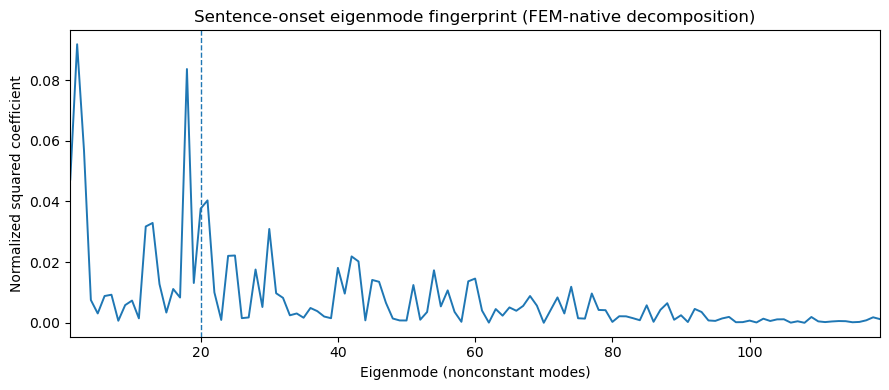

In [11]:
import matplotlib.pyplot as plt

modes = np.arange(1, 120)

# Hemisphere-specific and bihemispheric fingerprints.
# Average normalized power profiles across hemispheres so each hemisphere
# contributes equally despite small differences in valid surface area.
fingerprint = {}

for hemi in ["L", "R"]:
    a = decomp[hemi]["a119_M"]
    power = a**2
    power_norm = power / power.sum()
    fingerprint[hemi] = {
        "a": a,
        "power": power,
        "power_norm": power_norm,
        "cum_power_norm": np.cumsum(power_norm),
    }

power_bihemi = 0.5 * (
    fingerprint["L"]["power_norm"] +
    fingerprint["R"]["power_norm"]
)
cum_bihemi = np.cumsum(power_bihemi)

print("FEM-native onset-map cumulative squared-coefficient concentration:")
for Kcut in [5, 10, 20, 30, 50]:
    print(f"  K={Kcut:2d}: {cum_bihemi[Kcut-1]*100:.3f}%")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(modes, power_bihemi, lw=1.4)
ax.axvline(20, ls="--", lw=1)
ax.set_xlabel("Eigenmode (nonconstant modes)")
ax.set_ylabel("Normalized squared coefficient")
ax.set_title("Sentence-onset eigenmode fingerprint (FEM-native decomposition)")
ax.set_xlim(1, 119)
plt.tight_layout()
plt.show()


## 26.4 Candidate Panel D: onset-map concentration versus empirical cortical energy

The scientifically relevant comparison is not merely whether the onset map is dominated by long wavelengths, because ongoing cortical activity itself has a low-mode-biased spectrum. Panel D should therefore compare the cumulative onset-map spectral profile above against the **nuisance-corrected empirical cortical modal-energy spectrum on the same analysis grid**.

This cell intentionally searches for an already-computed empirical participant/group profile rather than silently reconstructing one with a potentially different run grid. The comparator must be the corrected empirical spectrum used in the definitive concentration analysis above.


In [13]:
# ============================================================
# 26.4 Locate corrected empirical cortical-energy comparator
# ============================================================

# Expected final comparator:
# modes 1..119, nuisance-corrected empirical cortical modal
# energy, preferably on the same sentence-onset analysis grid.
#
# First inspect what is already present in the notebook
# namespace. We do NOT select anything automatically.

empirical_candidates = []

# Snapshot the namespace first: iterating directly over
# globals().items() can raise "dictionary changed size"
# in a Jupyter kernel.
namespace_snapshot = list(globals().items())

for name, obj in namespace_snapshot:

    if not isinstance(obj, np.ndarray):
        continue

    low = name.lower()

    if (
        ("emp" in low or "energy" in low)
        and obj.ndim in (1, 2)
        and obj.shape[-1] in (119, 120)
    ):
        empirical_candidates.append(
            (name, obj)
        )


print(
    "Candidate empirical energy arrays "
    "in notebook namespace:"
)

if len(empirical_candidates) == 0:
    print("  None found.")

else:
    for name, arr in empirical_candidates:

        print(
            f"  {name:55s} "
            f"shape={arr.shape} "
            f"finite={np.isfinite(arr).sum()} "
            f"min={np.nanmin(arr):.6g} "
            f"max={np.nanmax(arr):.6g}"
        )


# ------------------------------------------------------------
# Also inspect likely saved corrected-spectrum / concentration
# files. Print only; do not load or select automatically.
# ------------------------------------------------------------

print("\nLikely saved comparator files:")

search_roots = [
    BASE / "pang_out/nuisance_robustness",
    BASE / "pang_out/paper_figures",
]

keywords = (
    "energy",
    "spectrum",
    "concentration",
    "figure3",
)

found = []

for root in search_roots:

    if not root.exists():
        continue

    for p in root.rglob("*"):

        if not p.is_file():
            continue

        low = p.name.lower()

        if any(k in low for k in keywords):

            if p.suffix.lower() in (
                ".npy",
                ".npz",
                ".csv",
                ".tsv",
            ):
                found.append(p)


for p in sorted(set(found)):
    print(" ", p)


print(
    "\nNo comparator has been selected automatically."
)

print(
    "For final Panel D we need to establish exactly "
    "which saved object contains the nuisance-corrected "
    "empirical cortical modal-energy spectrum and how "
    "that spectrum was projected."
)

Candidate empirical energy arrays in notebook namespace:
  None found.

Likely saved comparator files:
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_empirical_spectrum/energy_K20_subject_corrected.csv
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_empirical_spectrum/energy_spectrum_group_FIG2_COMPAT.csv
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_empirical_spectrum/energy_spectrum_group_corrected.csv
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_empirical_spectrum/energy_spectrum_run_corrected.csv
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_empirical_spectrum/energy_spectrum_subject_FIG2_COMPAT.csv
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_empirical_spectrum/energy_spectrum_subject_corrected.csv
  /home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_validated_linguist

In [14]:
# ============================================================
# 26.5 Audit existing empirical-energy comparator files
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

NR = BASE / "pang_out/nuisance_robustness"

files_to_check = {
    "fig2_group":
        NR / "corrected_empirical_spectrum"
        / "energy_spectrum_group_corrected.csv",

    "fig2_subject":
        NR / "corrected_empirical_spectrum"
        / "energy_spectrum_subject_corrected.csv",

    "concentration_empirical_profiles":
        NR / "corrected_validated_linguistic_effects"
        / "corrected_participant_empirical_energy_profiles.csv",

    "old_concentration_participants":
        NR / "figure3_corrected"
        / "figure3D_corrected_participant_concentration.csv",

    "old_group_beta_profiles":
        NR / "figure3_corrected"
        / "figure3C_corrected_group_raw_beta_profiles.csv",
}


loaded = {}

for label, path in files_to_check.items():

    print("\n" + "=" * 75)
    print(label)
    print("=" * 75)
    print(path)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)
    loaded[label] = df

    print("shape:", df.shape)
    print("columns:")
    print(df.columns.tolist())

    print("\nhead:")
    print(df.head(10).to_string(index=False))

    print("\ndtypes:")
    print(df.dtypes)

    # Useful generic summaries
    for col in df.columns:

        low = col.lower()

        if low in ("subject", "participant", "participant_id"):
            print(
                f"\nunique {col}:",
                df[col].nunique()
            )

        if low in ("run", "run_id"):
            print(
                f"unique {col}:",
                df[col].nunique()
            )

        if low in ("mode", "k", "eigenmode"):
            vals = pd.to_numeric(
                df[col],
                errors="coerce"
            )

            print(
                f"{col} range:",
                np.nanmin(vals),
                "to",
                np.nanmax(vals),
                "; unique =",
                pd.Series(vals).nunique()
            )


# ------------------------------------------------------------
# Specifically inspect the old participant concentration file
# for sentence onset.
# ------------------------------------------------------------

if "old_concentration_participants" in loaded:

    df = loaded["old_concentration_participants"].copy()

    print("\n" + "=" * 75)
    print("SENTENCE-ONSET ROWS IN OLD CONCENTRATION FILE")
    print("=" * 75)

    # Find likely predictor/effect column automatically
    pred_cols = [
        c for c in df.columns
        if c.lower() in (
            "predictor",
            "effect",
            "regressor",
            "metric"
        )
    ]

    if pred_cols:

        pc = pred_cols[0]

        print("predictor column:", pc)
        print(
            "unique values:",
            df[pc].unique()
        )

        onset = df[
            df[pc].astype(str)
            .str.lower()
            .str.contains("onset")
        ].copy()

        print("\nonset shape:", onset.shape)
        print(onset.head(20).to_string(index=False))

    else:
        print(
            "No obvious predictor/effect column; "
            "inspect table above manually."
        )


print(
    "\nAudit complete. No file has been adopted "
    "as the new FEM comparator yet."
)


fig2_group
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/corrected_empirical_spectrum/energy_spectrum_group_corrected.csv
shape: (120, 6)
columns:
['mode', 'energy', 'sd', 'sem', 'n', 'energy_norm']

head:
 mode     energy        sd      sem  n  energy_norm
    0 126.735219 60.392349 8.627478 49          NaN
    1  28.391933  5.749513 0.821359 49     0.042855
    2  37.501096 10.041308 1.434473 49     0.056604
    3  42.379897  7.256753 1.036679 49     0.063969
    4  17.468783  2.816764 0.402395 49     0.026368
    5  12.455527  3.632155 0.518879 49     0.018800
    6  13.990052  2.258437 0.322634 49     0.021117
    7  19.949204  3.140115 0.448588 49     0.030111
    8  10.904710  1.299748 0.185678 49     0.016460
    9  22.937670  3.404607 0.486372 49     0.034622

dtypes:
mode             int64
energy         float64
sd             float64
sem            float64
n                int64
energy_norm    float64
dtype: object
mode range: 0 to 119 ; unique = 120

fig

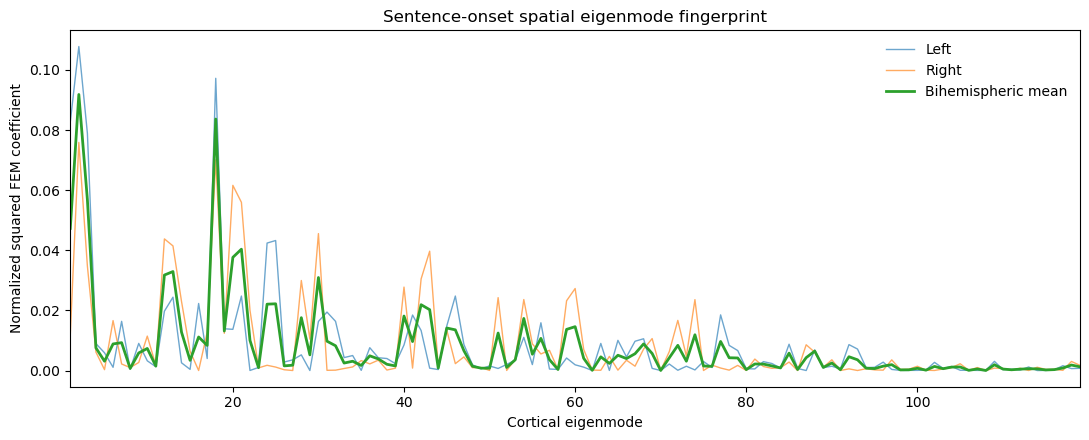

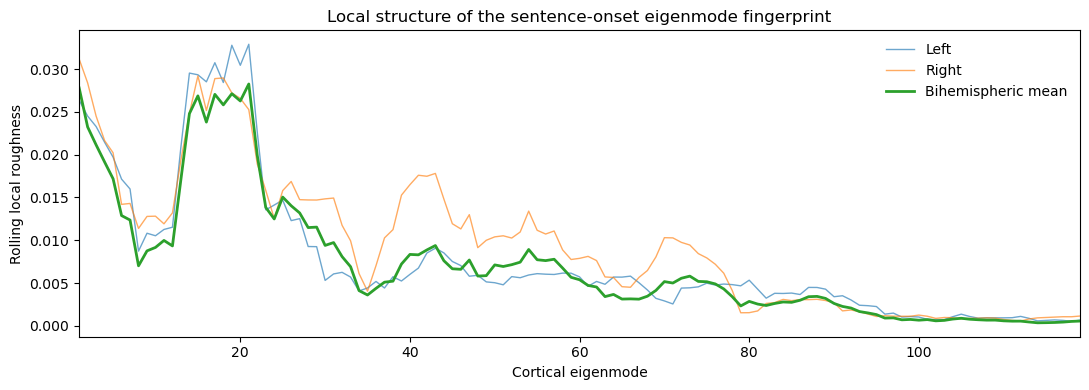

,modes,L_fraction_pct,R_fraction_pct,mean_fraction_pct,mean_roughness
0,1-10,31.427949,16.274121,23.851035,0.015871
1,11-20,19.941812,27.308019,23.624916,0.021823
2,21-30,13.938055,16.593871,15.265963,0.014920
3,31-40,7.175069,3.970213,5.572641,0.006273
4,41-60,12.714312,21.798688,17.256500,0.007267
5,61-80,8.771774,9.051248,8.911511,0.004152
6,81-119,6.031029,5.003839,5.517434,0.001353



Bihemispheric cumulative squared-coefficient fraction:
K=  5:  20.65%
K= 10:  23.85%
K= 20:  47.48%
K= 30:  62.74%
K= 40:  68.31%
K= 50:  77.30%
K= 60:  85.57%
K= 80:  94.48%
K=100:  98.64%
K=119: 100.00%

NOTE: roughness and broad-band summaries are exploratory descriptions of the fingerprint, not statistical tests or data-derived definitions of a low-order cutoff.


In [15]:
# ============================================================
# 26.6 Diagnose structure across the full onset fingerprint
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Construct hemisphere-specific normalized squared-coefficient
# fingerprints from the full 119-mode FEM fits.
# ------------------------------------------------------------

fp = {}

for hemi in ["L", "R"]:

    a = decomp[hemi]["a119_M"].copy()

    power = a ** 2
    power_norm = power / power.sum()

    fp[hemi] = {
        "a": a,
        "power_norm": power_norm,
    }


modes = np.arange(1, 120)

# Equal-weight bihemispheric average
power_mean = 0.5 * (
    fp["L"]["power_norm"]
    + fp["R"]["power_norm"]
)


# ------------------------------------------------------------
# Rolling roughness
#
# Rather than use variance of the raw spectrum—which would be
# strongly influenced by its overall amplitude/decay—we quantify
# local point-to-point irregularity:
#
#       |p(k+1) - p(k)|
#
# and average this within a rolling window.
#
# This is purely descriptive/exploratory.
# ------------------------------------------------------------

def rolling_roughness(x, window=9):

    x = np.asarray(x, float)

    # Point-to-point spectral differences
    d = np.abs(np.diff(x))

    # Associate differences with midpoint modes
    rough = np.full(len(x), np.nan)

    half = window // 2

    for i in range(len(x)):

        lo = max(0, i - half)
        hi = min(len(d), i + half + 1)

        if hi > lo:
            rough[i] = np.mean(d[lo:hi])

    return rough


rough_L = rolling_roughness(
    fp["L"]["power_norm"],
    window=9
)

rough_R = rolling_roughness(
    fp["R"]["power_norm"],
    window=9
)

rough_mean = rolling_roughness(
    power_mean,
    window=9
)


# ------------------------------------------------------------
# Plot 1: full normalized squared-coefficient fingerprint
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 4.5)
)

ax.plot(
    modes,
    fp["L"]["power_norm"],
    lw=1.0,
    alpha=0.65,
    label="Left"
)

ax.plot(
    modes,
    fp["R"]["power_norm"],
    lw=1.0,
    alpha=0.65,
    label="Right"
)

ax.plot(
    modes,
    power_mean,
    lw=2.0,
    label="Bihemispheric mean"
)

ax.set_xlabel(
    "Cortical eigenmode"
)

ax.set_ylabel(
    "Normalized squared FEM coefficient"
)

ax.set_title(
    "Sentence-onset spatial eigenmode fingerprint"
)

ax.set_xlim(
    1,
    119
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Plot 2: rolling local roughness
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 4.0)
)

ax.plot(
    modes,
    rough_L,
    lw=1.0,
    alpha=0.65,
    label="Left"
)

ax.plot(
    modes,
    rough_R,
    lw=1.0,
    alpha=0.65,
    label="Right"
)

ax.plot(
    modes,
    rough_mean,
    lw=2.0,
    label="Bihemispheric mean"
)

ax.set_xlabel(
    "Cortical eigenmode"
)

ax.set_ylabel(
    "Rolling local roughness"
)

ax.set_title(
    "Local structure of the sentence-onset eigenmode fingerprint"
)

ax.set_xlim(
    1,
    119
)

ax.legend(
    frameon=False
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Descriptive summaries in broad spectral bands.
#
# These bands are deliberately coarse and are NOT inferential
# cutoffs. They simply help us inspect where the coefficient
# structure is concentrated.
# ------------------------------------------------------------

bands = [
    (1, 10),
    (11, 20),
    (21, 30),
    (31, 40),
    (41, 60),
    (61, 80),
    (81, 119),
]

rows = []

for lo, hi in bands:

    idx = (
        (modes >= lo)
        & (modes <= hi)
    )

    rows.append({
        "modes": f"{lo}-{hi}",
        "L_fraction_pct":
            100 * fp["L"]["power_norm"][idx].sum(),
        "R_fraction_pct":
            100 * fp["R"]["power_norm"][idx].sum(),
        "mean_fraction_pct":
            100 * power_mean[idx].sum(),
        "mean_roughness":
            np.nanmean(rough_mean[idx]),
    })


band_summary = pd.DataFrame(rows)

display(band_summary)


# ------------------------------------------------------------
# Cumulative descriptive values.
# ------------------------------------------------------------

cum = np.cumsum(power_mean)

print("\nBihemispheric cumulative squared-coefficient fraction:")

for K in [
    5,
    10,
    20,
    30,
    40,
    50,
    60,
    80,
    100,
    119,
]:

    print(
        f"K={K:3d}: "
        f"{100*cum[K-1]:6.2f}%"
    )


print(
    "\nNOTE: roughness and broad-band summaries are exploratory "
    "descriptions of the fingerprint, not statistical tests or "
    "data-derived definitions of a low-order cutoff."
)

In [20]:
# ============================================================
# Locate definitive Panel A vertex-space null distribution
# ============================================================

VERTEX_ROOT = (
    BASE
    / "pang_out/nuisance_robustness"
    / "vertex_space_linguistic_encoding"
    / "onset_vertexwise_null_10000"
)

print("Searching under:")
print(VERTEX_ROOT)

panelA_candidates = []

for p in VERTEX_ROOT.rglob("*"):

    if not p.is_file():
        continue

    name = p.name.lower()

    if any(
        key in name
        for key in [
            "null",
            "rms",
            "summary",
            "permutation",
            "perm",
        ]
    ):
        panelA_candidates.append(p)

for p in panelA_candidates:
    print(p)

Searching under:
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000/rms_00700_00799.csv
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000/rms_08100_08199.csv
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000/rms_04300_04399.csv
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000/rms_01600_01699.csv
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_10000/rms_06400_06499.csv
/home/whinzen/eigenmode_fingerprints/pang_out/nuisance_robustness/vertex_space_linguistic_encoding/onset_vertexwise_null_

In [21]:
# ============================================================
# Recover and verify the definitive 10,000-permutation
# vertex-space RMS null used for Panel A
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import re

VERTEX_ROOT = (
    BASE
    / "pang_out/nuisance_robustness"
    / "vertex_space_linguistic_encoding"
    / "onset_vertexwise_null_10000"
)

rms_files = sorted(
    VERTEX_ROOT.glob("rms_*.csv")
)

print("RMS chunk files:", len(rms_files))

assert len(rms_files) == 100, (
    f"Expected 100 RMS chunks, found {len(rms_files)}"
)


# ------------------------------------------------------------
# Verify that filenames cover 00000..09999 continuously
# ------------------------------------------------------------

ranges = []

for p in rms_files:

    m = re.fullmatch(
        r"rms_(\d{5})_(\d{5})\.csv",
        p.name
    )

    assert m is not None, p.name

    lo = int(m.group(1))
    hi = int(m.group(2))

    ranges.append((lo, hi, p))


ranges = sorted(
    ranges,
    key=lambda x: x[0]
)

expected = 0

for lo, hi, p in ranges:

    assert lo == expected, (
        f"Gap/overlap before {p.name}: "
        f"expected {expected}, got {lo}"
    )

    assert hi - lo + 1 == 100, (
        f"Unexpected chunk size in {p.name}"
    )

    expected = hi + 1

assert expected == 10000

print("PASS: filenames span permutations 0..9999 exactly.")


# ------------------------------------------------------------
# Inspect first chunk before assuming its column structure
# ------------------------------------------------------------

first = pd.read_csv(
    ranges[0][2]
)

print("\nFirst chunk:")
print(first.head())
print("columns:", first.columns.tolist())
print("shape:", first.shape)


# ------------------------------------------------------------
# Identify RMS column
# ------------------------------------------------------------

rms_cols = [
    c for c in first.columns
    if "rms" in c.lower()
]

if len(rms_cols) != 1:
    raise RuntimeError(
        "Could not uniquely identify RMS column. "
        f"Candidates: {rms_cols}; "
        f"all columns: {first.columns.tolist()}"
    )

rms_col = rms_cols[0]

print("Using RMS column:", rms_col)


# ------------------------------------------------------------
# Concatenate all 10,000 null values
# ------------------------------------------------------------

null_parts = []

for lo, hi, p in ranges:

    d = pd.read_csv(p)

    assert rms_col in d.columns

    vals = pd.to_numeric(
        d[rms_col],
        errors="raise"
    ).to_numpy()

    assert len(vals) == 100, (
        f"{p.name}: expected 100 values, "
        f"found {len(vals)}"
    )

    null_parts.append(vals)


null_rms = np.concatenate(
    null_parts
)

assert len(null_rms) == 10000
assert np.all(np.isfinite(null_rms))

print("\nRecovered null:")
print("n =", len(null_rms))
print("mean =", null_rms.mean())
print("SD =", null_rms.std(ddof=1))
print(
    "range =",
    null_rms.min(),
    "to",
    null_rms.max()
)


# ------------------------------------------------------------
# HARD provenance check against definitive observed statistic
# ------------------------------------------------------------

empirical_rms = 0.0077368728815637

# +1 correction used for finite permutation tests
n_ge = np.sum(
    null_rms >= empirical_rms
)

p_recovered = (
    (n_ge + 1)
    / (len(null_rms) + 1)
)

print("\nObserved RMS =", empirical_rms)
print("Null >= observed =", n_ge)
print("Recovered p =", p_recovered)

p_expected = 0.035996400359964

assert np.isclose(
    p_recovered,
    p_expected,
    atol=1e-12
), (
    "Recovered null does NOT reproduce "
    "the definitive p-value."
)

print(
    "\nPASS: recovered 10,000-permutation RMS null "
    "exactly reproduces the definitive "
    "vertex-space p-value."
)

RMS chunk files: 100
PASS: filenames span permutations 0..9999 exactly.

First chunk:
   perm       predictor  group_map_rms
0     0  sentence_onset       0.006512
1     1  sentence_onset       0.005295
2     2  sentence_onset       0.005877
3     3  sentence_onset       0.005384
4     4  sentence_onset       0.005476
columns: ['perm', 'predictor', 'group_map_rms']
shape: (100, 3)
Using RMS column: group_map_rms

Recovered null:
n = 10000
mean = 0.0058027706754666996
SD = 0.0009428454037109132
range = 0.0035423960640672 to 0.0110873232585873

Observed RMS = 0.0077368728815637
Null >= observed = 359
Recovered p = 0.035996400359964

PASS: recovered 10,000-permutation RMS null exactly reproduces the definitive vertex-space p-value.


Panel A provenance PASS: N=10000, null mean=0.005802771, observed=0.007736873, p=0.035996400
Panel B FEM provenance PASS: L R²=0.608818, R R²=0.496229
Panel D participant inference PASS: Cβ=52.74%, CE=46.60%, D=6.14 pp


/tmp/ipykernel_3201138/3401975234.py:823: DeprecationWarning: The `darkness` parameter will be deprecated in release 0.13. We recommend setting `darkness` to None
  plotting.plot_surf_stat_map(


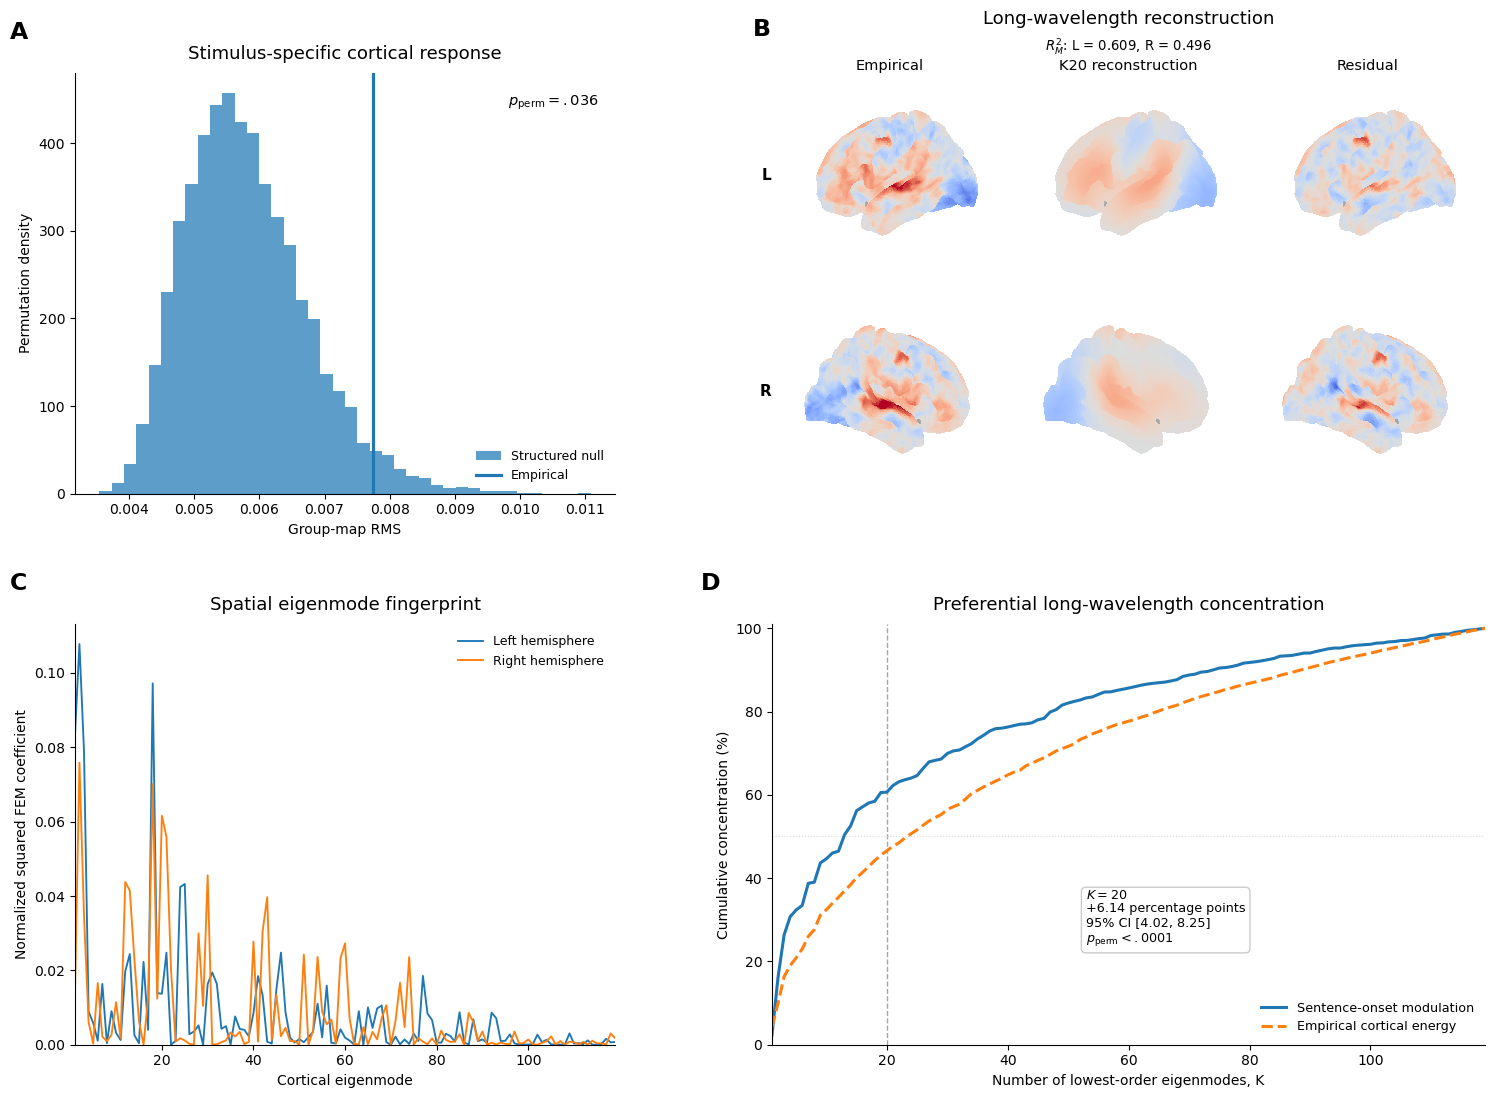


Saved:
/home/whinzen/eigenmode_fingerprints/pang_out/paper_figures/sentence_onset_integrated_FEM/sentence_onset_integrated_FEM_REVISED.png
/home/whinzen/eigenmode_fingerprints/pang_out/paper_figures/sentence_onset_integrated_FEM/sentence_onset_integrated_FEM_REVISED.pdf

FINAL QC
A: RMS=0.007737, p_perm=0.035996
B: FEM K20 R² L=0.609, R=0.496
D: K20 paired excess=6.14 pp


In [22]:
# ============================================================
# FINAL INTEGRATED SENTENCE-ONSET FIGURE — FEM VERSION
#
# A  Conventional vertex-space structured-null validation
# B  FEM-native K20 spatial reconstruction
# C  Bilateral full FEM eigenmode fingerprint
# D  Independent cumulative modal-energy concentration
#
# Definitive corrected cortical pipeline.
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm

from lapy import TriaMesh, Solver
from nilearn import plotting


# ============================================================
# PATHS
# ============================================================

BASE = Path.home() / "eigenmode_fingerprints"

NR = (
    BASE
    / "pang_out/nuisance_robustness"
)

VERTEX_ROOT = (
    NR
    / "vertex_space_linguistic_encoding"
    / "onset_vertexwise_null_10000"
)

INF = (
    VERTEX_ROOT
    / "inference"
)

FIG3 = (
    NR
    / "figure3_corrected"
)

VALIDATED = (
    NR
    / "corrected_validated_linguistic_effects"
)

OUT = (
    BASE
    / "pang_out/paper_figures"
    / "sentence_onset_integrated_FEM"
)

OUT.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# A. RECOVER DEFINITIVE 10,000-PERMUTATION RMS NULL
# ============================================================

rms_files = sorted(
    VERTEX_ROOT.glob("rms_*.csv")
)

assert len(rms_files) == 100

ranges = []

for p in rms_files:

    m = re.fullmatch(
        r"rms_(\d{5})_(\d{5})\.csv",
        p.name
    )

    assert m is not None

    ranges.append(
        (
            int(m.group(1)),
            int(m.group(2)),
            p,
        )
    )

ranges = sorted(
    ranges,
    key=lambda x: x[0]
)

expected = 0
null_parts = []

for lo, hi, p in ranges:

    assert lo == expected
    assert hi - lo + 1 == 100

    d = pd.read_csv(p)

    assert "group_map_rms" in d.columns
    assert len(d) == 100

    null_parts.append(
        d["group_map_rms"]
        .to_numpy(float)
    )

    expected = hi + 1

assert expected == 10000

null_rms = np.concatenate(
    null_parts
)

assert len(null_rms) == 10000


empirical_rms = 0.0077368728815637

n_ge = int(
    np.sum(
        null_rms >= empirical_rms
    )
)

p_vertex = (
    n_ge + 1
) / (
    len(null_rms) + 1
)

assert n_ge == 359

assert np.isclose(
    p_vertex,
    0.035996400359964,
    atol=1e-14
)

print(
    "Panel A provenance PASS:",
    f"N={len(null_rms)},",
    f"null mean={null_rms.mean():.9f},",
    f"observed={empirical_rms:.9f},",
    f"p={p_vertex:.9f}"
)


# ============================================================
# B/C. LOAD DEFINITIVE CONVENTIONAL ONSET MAPS
# ============================================================

pathL = (
    INF
    / "sentence_onset_beta_star_L.npy"
)

pathR = (
    INF
    / "sentence_onset_beta_star_R.npy"
)

assert pathL.exists()
assert pathR.exists()

yL_full = np.load(pathL)
yR_full = np.load(pathR)

assert yL_full.shape == (10242,)
assert yR_full.shape == (10242,)


# Verified encoding:
# never-valid vertices are exact zero.
validL = yL_full != 0
validR = yR_full != 0

assert validL.sum() == 9354
assert validR.sum() == 9361


# ============================================================
# LOAD EXACT FEM BASIS
# ============================================================

phiL = np.load(
    BASE
    / "data/template_eigenmodes/fsaverage5/phi_L.npy"
)

phiR = np.load(
    BASE
    / "data/template_eigenmodes/fsaverage5/phi_R.npy"
)

assert phiL.shape == (10242, 120)
assert phiR.shape == (10242, 120)


# ============================================================
# EXACT WHITE-SURFACE FEM MESHES
# ============================================================

surfL_vtk = (
    BASE
    / "pang_surfaces/fsaverage5/lh.white.vtk"
)

surfR_vtk = (
    BASE
    / "pang_surfaces/fsaverage5/rh.white.vtk"
)

triaL = TriaMesh.read_vtk(
    str(surfL_vtk)
)

triaR = TriaMesh.read_vtk(
    str(surfR_vtk)
)

femL = Solver(triaL)
femR = Solver(triaR)

M_L = femL.mass
M_R = femR.mass


# Nilearn-compatible meshes
surf_plot = {
    "L": (
        np.asarray(triaL.v),
        np.asarray(triaL.t),
    ),
    "R": (
        np.asarray(triaR.v),
        np.asarray(triaR.t),
    ),
}


# ============================================================
# FEM HELPERS
# ============================================================

def masked_mass_matrix(M, mask):

    idx = np.flatnonzero(mask)

    return M[idx][:, idx]


def weighted_mean(y, M):

    one = np.ones(len(y))

    return float(
        (one @ (M @ y))
        /
        (one @ (M @ one))
    )


def weighted_fit(Phi, y, M):

    G = Phi.T @ (M @ Phi)
    b = Phi.T @ (M @ y)

    return np.linalg.solve(
        G,
        b
    )


def weighted_r2(y, yhat, M):

    mu = weighted_mean(
        y,
        M
    )

    resid = y - yhat
    centered = y - mu

    return (
        1.0
        -
        (
            resid @ (M @ resid)
        )
        /
        (
            centered @ (M @ centered)
        )
    )


# ============================================================
# FEM FITS
#
# IMPORTANT:
# K20 and K119 fitted independently.
# K20 is NOT truncated from K119.
# ============================================================

fit = {}

for hemi, yfull, valid, phi, Mfull in [

    (
        "L",
        yL_full,
        validL,
        phiL,
        M_L,
    ),

    (
        "R",
        yR_full,
        validR,
        phiR,
        M_R,
    ),

]:

    y = yfull[
        valid
    ].copy()

    M = masked_mass_matrix(
        Mfull,
        valid
    )

    mu = weighted_mean(
        y,
        M
    )

    y0 = y - mu

    Phi20 = phi[
        valid,
        1:21
    ]

    Phi119 = phi[
        valid,
        1:120
    ]

    # Independent fits
    a20 = weighted_fit(
        Phi20,
        y0,
        M
    )

    a119 = weighted_fit(
        Phi119,
        y0,
        M
    )

    yhat20 = (
        Phi20 @ a20
    )

    resid20 = (
        y0 - yhat20
    )

    r2 = weighted_r2(
        y0,
        yhat20,
        M
    )

    empirical_full = np.full(
        len(yfull),
        np.nan
    )

    recon_full = np.full(
        len(yfull),
        np.nan
    )

    resid_full = np.full(
        len(yfull),
        np.nan
    )

    empirical_full[
        valid
    ] = y0

    recon_full[
        valid
    ] = yhat20

    resid_full[
        valid
    ] = resid20


    # Full fingerprint
    sq = a119 ** 2

    sq_norm = (
        sq
        /
        sq.sum()
    )


    fit[hemi] = {
        "empirical":
            empirical_full,

        "recon":
            recon_full,

        "residual":
            resid_full,

        "a20":
            a20,

        "a119":
            a119,

        "power_norm":
            sq_norm,

        "r2":
            r2,

        "mean_removed":
            mu,
    }


# Hard expected FEM results
assert np.isclose(
    fit["L"]["r2"],
    0.6088176832248662
)

assert np.isclose(
    fit["R"]["r2"],
    0.4962294869175967
)

print(
    "Panel B FEM provenance PASS:",
    f"L R²={fit['L']['r2']:.6f},",
    f"R R²={fit['R']['r2']:.6f}"
)


# ============================================================
# D. LOAD DEFINITIVE PARTICIPANT-PAIRED CONCENTRATION
# ============================================================

conc_path = (
    FIG3
    / "figure3D_corrected_participant_concentration.csv"
)

conc = pd.read_csv(
    conc_path
)

conc_onset = (
    conc[
        conc["effect"]
        == "Sentence onset"
    ]
    .copy()
)

assert (
    conc_onset["subject"]
    .nunique()
    == 49
)


# ============================================================
# D. BUILD FULL CUMULATIVE CURVES
#
# We reconstruct the DISPLAYED curves from the same underlying
# objects used by the definitive concentration analysis:
#
#   linguistic: group raw partial-beta profile
#   comparator: participant empirical energy profiles
#
# The formal inference remains participant-paired at K20.
# ============================================================

beta_group_path = (
    FIG3
    / "figure3C_corrected_group_raw_beta_profiles.csv"
)

energy_sub_path = (
    VALIDATED
    / "corrected_participant_empirical_energy_profiles.csv"
)

beta_group = pd.read_csv(
    beta_group_path
)

energy_sub = pd.read_csv(
    energy_sub_path
)


# Sentence onset only
bg = (
    beta_group[
        beta_group["effect"]
        == "Sentence onset"
    ]
    .sort_values("mode")
    .copy()
)

assert len(bg) == 119
assert np.array_equal(
    bg["mode"].to_numpy(),
    np.arange(1, 120)
)


# Group raw-beta cumulative curve
beta_abs = np.abs(
    bg["beta_mean"]
    .to_numpy(float)
)

cum_beta = (
    np.cumsum(beta_abs)
    /
    beta_abs.sum()
)


# Exact sentence-onset empirical-energy profiles
es = (
    energy_sub[
        energy_sub["predictor"]
        == "Sentence onset"
    ]
    .copy()
)

assert es["subject"].nunique() == 49
assert es["mode"].nunique() == 119


# Participant energy -> group mean profile,
# preserving participant hierarchy.
energy_group = (
    es
    .groupby(
        "mode",
        as_index=False
    )["energy"]
    .mean()
    .sort_values("mode")
)

assert np.array_equal(
    energy_group["mode"].to_numpy(),
    np.arange(1, 120)
)

E = energy_group[
    "energy"
].to_numpy(float)

cum_energy = (
    np.cumsum(E)
    /
    E.sum()
)


# ============================================================
# HARD K20 CHECK AGAINST DEFINITIVE PARTICIPANT INFERENCE
# ============================================================

K20 = (
    conc_onset[
        conc_onset["K"] == 20
    ]
    .copy()
)

mean_Cbeta_K20 = (
    K20["C_beta"].mean()
)

mean_Cenergy_K20 = (
    K20["C_energy"].mean()
)

mean_D_K20 = (
    K20["D"].mean()
)

assert np.isclose(
    mean_Cbeta_K20,
    0.5274091773972147,
    atol=1e-12
)

assert np.isclose(
    mean_Cenergy_K20,
    0.46601078427231457,
    atol=1e-12
)

assert np.isclose(
    mean_D_K20,
    0.0613983931249001,
    atol=1e-12
)

print(
    "Panel D participant inference PASS:",
    f"Cβ={100*mean_Cbeta_K20:.2f}%,",
    f"CE={100*mean_Cenergy_K20:.2f}%,",
    f"D={100*mean_D_K20:.2f} pp"
)


# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(
    figsize=(15.5, 11.3)
)

outer = GridSpec(
    2,
    2,
    figure=fig,
    width_ratios=[
        1.0,
        1.32,
    ],
    height_ratios=[
        1.0,
        1.0,
    ],
    wspace=0.25,
    hspace=0.31,
)


# ============================================================
# PANEL A
# ============================================================

axA = fig.add_subplot(
    outer[0, 0]
)

axA.hist(
    null_rms,
    bins=40,
    density=True,
    alpha=0.72,
    edgecolor="none",
    label="Structured null"
)

axA.axvline(
    empirical_rms,
    lw=2.3,
    label="Empirical"
)

axA.set_xlabel(
    "Group-map RMS"
)

axA.set_ylabel(
    "Permutation density"
)

axA.set_title(
    "Stimulus-specific cortical response",
    fontsize=13,
    pad=10
)

axA.legend(
    frameon=False,
    fontsize=9
)

axA.text(
    0.97,
    0.95,
    r"$p_{\mathrm{perm}}=.036$",
    transform=axA.transAxes,
    ha="right",
    va="top",
    fontsize=10.5
)

axA.text(
    -0.12,
    1.08,
    "A",
    transform=axA.transAxes,
    fontsize=17,
    fontweight="bold"
)

axA.spines[
    ["top", "right"]
].set_visible(False)


# ============================================================
# PANEL B
# ============================================================

gsB = outer[
    0,
    1
].subgridspec(
    2,
    3,
    wspace=0.015,
    hspace=0.06
)


# Gentler shared scale.
#
# Increasing percentile relative to the previous 99th-percentile
# scale reduces saturation while retaining one common scale.
emp_values = np.concatenate([
    fit["L"]["empirical"][
        np.isfinite(
            fit["L"]["empirical"]
        )
    ],
    fit["R"]["empirical"][
        np.isfinite(
            fit["R"]["empirical"]
        )
    ],
])

vmax = np.percentile(
    np.abs(emp_values),
    99.7
)

vmin = -vmax


B_titles = [
    "Empirical",
    "K20 reconstruction",
    "Residual",
]

B_keys = [
    "empirical",
    "recon",
    "residual",
]

axesB = {}


for row, hemi in enumerate(
    ["L", "R"]
):

    for col, key in enumerate(
        B_keys
    ):

        ax = fig.add_subplot(
            gsB[
                row,
                col
            ],
            projection="3d"
        )

        axesB[
            (hemi, key)
        ] = ax


        plotting.plot_surf_stat_map(
            surf_plot[hemi],
            fit[hemi][key],
            hemi=(
                "left"
                if hemi == "L"
                else "right"
            ),
            view="lateral",
            cmap="coolwarm",
            vmin=vmin,
            vmax=vmax,
            symmetric_cbar=True,
            colorbar=False,
            axes=ax,
        )


        if row == 0:

            ax.set_title(
                B_titles[col],
                fontsize=10.5,
                pad=0
            )


        if col == 0:

            ax.text2D(
                -0.08,
                0.50,
                hemi,
                transform=ax.transAxes,
                ha="right",
                va="center",
                fontsize=11,
                fontweight="bold"
            )


# B panel label
axesB[
    ("L", "empirical")
].text2D(
    -0.17,
    1.18,
    "B",
    transform=axesB[
        ("L", "empirical")
    ].transAxes,
    fontsize=17,
    fontweight="bold"
)


# Main B title
axesB[
    ("L", "recon")
].text2D(
    0.5,
    1.22,
    "Long-wavelength reconstruction",
    transform=axesB[
        ("L", "recon")
    ].transAxes,
    ha="center",
    va="bottom",
    fontsize=13
)


# Put BOTH R² values together in guaranteed visible space.
axesB[
    ("L", "recon")
].text2D(
    0.5,
    1.08,
    (
        rf"$R_M^2$: "
        rf"L = {fit['L']['r2']:.3f}, "
        rf"R = {fit['R']['r2']:.3f}"
    ),
    transform=axesB[
        ("L", "recon")
    ].transAxes,
    ha="center",
    va="bottom",
    fontsize=9.5
)


# ============================================================
# PANEL C — FULL BILATERAL FEM FINGERPRINT
# ============================================================

axC = fig.add_subplot(
    outer[1, 0]
)

modes = np.arange(
    1,
    120
)

axC.plot(
    modes,
    fit["L"]["power_norm"],
    lw=1.35,
    label="Left hemisphere"
)

axC.plot(
    modes,
    fit["R"]["power_norm"],
    lw=1.35,
    label="Right hemisphere"
)

axC.set_xlim(
    1,
    119
)

axC.set_ylim(
    bottom=0
)

axC.set_xlabel(
    "Cortical eigenmode"
)

axC.set_ylabel(
    "Normalized squared FEM coefficient"
)

axC.set_title(
    "Spatial eigenmode fingerprint",
    fontsize=13,
    pad=10
)

axC.legend(
    frameon=False,
    fontsize=9
)

axC.text(
    -0.12,
    1.08,
    "C",
    transform=axC.transAxes,
    fontsize=17,
    fontweight="bold"
)

axC.spines[
    ["top", "right"]
].set_visible(False)


# ============================================================
# PANEL D — TWO CUMULATIVE CURVES
# ============================================================

axD = fig.add_subplot(
    outer[1, 1]
)


axD.plot(
    modes,
    100 * cum_beta,
    lw=2.2,
    label="Sentence-onset modulation"
)

axD.plot(
    modes,
    100 * cum_energy,
    lw=2.2,
    ls="--",
    label="Empirical cortical energy"
)


# K20 is an inferential reference, NOT a claimed boundary.
axD.axvline(
    20,
    color="0.65",
    lw=1.0,
    ls="--",
    zorder=0
)


# Useful visual reference only
axD.axhline(
    50,
    color="0.85",
    lw=0.8,
    ls=":",
    zorder=0
)


axD.set_xlim(
    1,
    119
)

axD.set_ylim(
    0,
    101
)

axD.set_xlabel(
    "Number of lowest-order eigenmodes, K"
)

axD.set_ylabel(
    "Cumulative concentration (%)"
)

axD.set_title(
    "Preferential long-wavelength concentration",
    fontsize=13,
    pad=10
)


# Formal participant-paired result.
#
# Note that the displayed group curves are descriptive;
# inference comes from participant-paired C_beta - C_energy.
annotation = (
    "$K=20$\n"
    "+6.14 percentage points\n"
    "95% CI [4.02, 8.25]\n"
    r"$p_{\mathrm{perm}}<.0001$"
)

axD.text(
    0.44,
    0.30,
    annotation,
    transform=axD.transAxes,
    ha="left",
    va="center",
    fontsize=9.2,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="0.78",
        alpha=0.92
    )
)


axD.legend(
    frameon=False,
    fontsize=9.2,
    loc="lower right"
)

axD.text(
    -0.10,
    1.08,
    "D",
    transform=axD.transAxes,
    fontsize=17,
    fontweight="bold"
)

axD.spines[
    ["top", "right"]
].set_visible(False)


# ============================================================
# FINAL LAYOUT / EXPORT
# ============================================================

# I would omit a global title in the manuscript figure.
# The caption will carry the overarching statement.

plt.subplots_adjust(
    top=0.94,
    bottom=0.08,
    left=0.07,
    right=0.98
)


png = (
    OUT
    / "sentence_onset_integrated_FEM_REVISED.png"
)

pdf = (
    OUT
    / "sentence_onset_integrated_FEM_REVISED.pdf"
)


fig.savefig(
    png,
    dpi=400,
    bbox_inches="tight"
)

fig.savefig(
    pdf,
    bbox_inches="tight"
)

plt.show()


print("\nSaved:")
print(png)
print(pdf)

print("\nFINAL QC")
print(
    f"A: RMS={empirical_rms:.6f}, "
    f"p_perm={p_vertex:.6f}"
)

print(
    f"B: FEM K20 R² "
    f"L={fit['L']['r2']:.3f}, "
    f"R={fit['R']['r2']:.3f}"
)

print(
    f"D: K20 paired excess="
    f"{100*mean_D_K20:.2f} pp"
)

### Interpretation checkpoint

The main-figure architecture will be frozen only after the numerical comparison above is complete:

**A. Vertex-space stimulus-specific validation**  
The conventional sentence-onset cortical response survives the historical structured temporal null.

**B. Spatial reconstruction**  
The validated onset map is reconstructed from the first 20 nonconstant cortical eigenmodes, with the FEM-native result primary and ordinary least squares retained as a sensitivity analysis.

**C. Eigenmode fingerprint**  
The same validated onset map is expressed across the full nonconstant FEM basis.

**D. Preferential long-wavelength concentration**  
The cumulative spectral profile of the onset map is compared with the nuisance-corrected empirical cortical modal-energy spectrum, testing whether sentence onset is more strongly concentrated toward long spatial wavelengths than ongoing cortical activity itself.

The historical modal-energy GLM concentration result (including the previously obtained K20 excess of approximately +6.14 percentage points) remains a separate convergent analysis and is not substituted for the new vertex-map decomposition.


# 27. Geometry-specificity control: folded cortical eigenmodes versus spherical eigenmodes

**Recovered 2026-10-01 from the analysis record after accidental notebook-cell deletion.** The intact notebook above is unchanged. The cells below reconstruct the geometry-specificity work completed after the FEM audit. Expensive derived products are loaded from their saved cluster outputs whenever possible rather than recomputed automatically.

The first question is whether the validated sentence-onset map specifically privileges the Laplace-Beltrami basis of the folded cortical surface, or whether a generic smooth harmonic basis performs similarly.

A matched spherical control was therefore constructed on the canonical fsaverage5 sphere using the same LaPy/FEM machinery as the cortical basis:

$$
S_{\mathrm{white}}\phi=\lambda M_{\mathrm{white}}\phi
$$

versus

$$
S_{\mathrm{sphere}}\psi=\mu M_{\mathrm{sphere}}\psi.
$$

The sphere has the same vertices and triangular topology but removes the specific metric geometry of cortical folding. For reconstruction/evaluation of cortical maps, both bases are evaluated with the **white-surface mass matrix**, because the response map lives on the actual cortical surface.

Complete spherical eigenspaces were used for the reconstruction comparison. Excluding the constant mode, the common complete dimensions available with the 119 nonconstant cortical modes are $K=3,8,15,24,35,48,63,80,99$.


In [ ]:
# 27.1 Load and QC the saved spherical FEM basis
from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path.home() / "eigenmode_fingerprints"
SPHERE_ROOT = BASE / "pang_out" / "geometry_specificity" / "sphere_control"

sphere_modes = {}
sphere_evals = {}
for hemi in ["L", "R"]:
    mf = SPHERE_ROOT / f"sphere_eigenmodes_{hemi}.npy"
    ef = SPHERE_ROOT / f"sphere_eigenvalues_{hemi}.npy"
    assert mf.exists(), mf
    assert ef.exists(), ef
    sphere_modes[hemi] = np.load(mf)
    sphere_evals[hemi] = np.load(ef)
    print(hemi, "sphere modes", sphere_modes[hemi].shape,
          "eigenvalues", sphere_evals[hemi].shape)
    assert sphere_modes[hemi].shape[0] == 10242
    assert sphere_modes[hemi].shape[1] >= 121

# Analytic spherical eigenvalues for radius R=100: ell(ell+1)/R^2.
# The saved FEM spectrum should show the expected 2ell+1 staircase degeneracy.
for hemi in ["L", "R"]:
    ev = sphere_evals[hemi]
    print("\n", hemi)
    start = 0
    for ell in range(0, 11):
        n = 2*ell + 1
        vals = ev[start:start+n]
        expected = ell*(ell+1)/10000.0
        rel = np.nan if expected == 0 else abs(vals.mean()-expected)/expected
        print(f"ell={ell:2d} n={n:2d} mean={vals.mean():.9f} expected={expected:.9f} rel.err={rel}")
        start += n


### 27.2 Spherical reconstruction result

The saved comparison showed **no general reconstruction advantage** for folded cortical geometry over the matched spherical basis. The direction changed across spatial scales.

| K | L: folded - sphere $R_M^2$ | R: folded - sphere $R_M^2$ |
|---:|---:|---:|
| 3 | +0.052430 | +0.065975 |
| 8 | +0.001178 | -0.018240 |
| 15 | -0.029900 | -0.033496 |
| 24 | +0.007943 | +0.010095 |
| 35 | +0.022172 | +0.018510 |
| 48 | +0.011053 | +0.015474 |
| 63 | +0.005821 | +0.011053 |
| 80 | -0.023620 | -0.030435 |
| 99 | -0.005248 | -0.028592 |

**Interpretation:** the sentence-onset map has pronounced low-dimensional / long-wavelength organization, but its reconstruction does not uniquely require detailed folded cortical metric geometry. This motivated a second control asking whether a data-driven functional basis compresses the response more efficiently.


# 28. Cross-validated functional PCA control

The second geometry-specificity question is whether the cortical LB basis is itself a privileged low-dimensional basis. A leave-one-participant-out (LOPO) spatial PCA was learned from nuisance-corrected BOLD without linguistic regressors.

For held-out participant $s$:

1. nuisance-corrected cortical BOLD from the other 48 participants was used;
2. the PCA basis was learned from training participants only;
3. participant $s$ never entered PCA training;
4. participant $s$'s sentence-onset $\beta^*$ map was estimated independently;
5. the held-out map was reconstructed with both PCA and the fixed cortical LB basis under the same white-surface FEM metric.

Thus the comparison is between a **geometry-only basis** and a **functional covariance basis learned from independent participants**.

A deterministic balanced sketch used 25 evenly spaced TRs from every cached run (439 runs; 10,975 observations). Randomized PCA used 100 components, `random_state=20261001`, and `iterated_power=4`. The frozen dimensionality grid is $K=[5,10,20,30,50,80,100]$.


In [ ]:
# 28.1 Verify the saved LOPO PCA products and participant beta-star provenance
PCA_ROOT = BASE / "pang_out" / "geometry_specificity" / "crossvalidated_pca"
PCA_BASES = PCA_ROOT / "lopo_bases"

for hemi, nvalid in [("L", 9354), ("R", 9358)]:
    mask = np.load(PCA_ROOT / f"common_valid_mask_{hemi}.npy").astype(bool)
    assert int(mask.sum()) == nvalid
    files = sorted((PCA_BASES / hemi).glob("sub-*_PCA100.npz"))
    print(hemi, "common-valid", mask.sum(), "LOPO bases", len(files))
    assert len(files) == 49
    d = np.load(files[0], allow_pickle=True)
    print(" example components:", d["components"].shape)
    assert d["components"].shape == (nvalid, 100)

qc = PCA_ROOT / "participant_onset_beta_star_provenance_QC.csv"
if qc.exists():
    display(pd.read_csv(qc))
else:
    print("Provenance QC CSV not found at", qc)

print("\nRecorded exact provenance QC:")
print("L group RMS reconstructed = 0.007527981203774354; definitive = 0.007527981203399227; corr = 1")
print("R group RMS reconstructed = 0.00794027096289259; definitive = 0.007940270963400435; corr = 1")


### 28.2 Definitive PCA-versus-LB reconstruction result

Cross-validated PCA reconstructed individual sentence-onset maps more efficiently than the cortical LB basis at every frozen $K$.

| K | LB $R_M^2$ | PCA $R_M^2$ | LB - PCA |
|---:|---:|---:|---:|
| 5 | .150259 | .210259 | -.060000 |
| 10 | .218568 | .313209 | -.094641 |
| 20 | .302087 | .416575 | -.114488 |
| 30 | .358856 | .466346 | -.107490 |
| 50 | .437871 | .526368 | -.088497 |
| 80 | .515745 | .576129 | -.060384 |
| 100 | .550804 | .599667 | -.048863 |

Across the whole curve PCA outperformed LB for 48/49 participants. At the historical $K=20$ reference:

$$
R^2_{\mathrm{LB}}=.302,
\qquad
R^2_{\mathrm{PCA}}=.417.
$$

This does **not** invalidate the eigenmode result: PCA has an informational advantage because it learns population functional covariance, whereas LB receives only surface geometry. It does rule out the stronger claim that the cortical geometric basis is a unique or optimal low-dimensional functional basis.


# 29. Direct functional-PCA versus folded-LB subspace comparison

To determine whether PCA learns a completely different functional space, we compared the two bases directly, without sentence-onset maps or linguistic regressors.

Each basis $B$ was orthonormalized under the white-surface FEM mass inner product:

$$
Q^T M Q = I.
$$

For the two subspaces,

$$
C = Q_{\mathrm{LB}}^T M Q_{\mathrm{PCA}}.
$$

The singular values satisfy $s_i=\cos\theta_i$, where $\theta_i$ are principal angles. The descriptive overlap statistic is

$$
O_K = \frac{1}{K}\sum_{i=1}^{K}\cos^2\theta_i.
$$


In [ ]:
# 29.1 Load the saved PCA-LB subspace comparison
SUBSPACE_ROOT = PCA_ROOT / "basis_subspace_comparison"
group_file = SUBSPACE_ROOT / "group_LB_PCA_subspace_overlap.csv"
hemi_file = SUBSPACE_ROOT / "hemisphere_LB_PCA_subspace_overlap.csv"
stability_file = SUBSPACE_ROOT / "fold_stability_LB_PCA_overlap.csv"

assert group_file.exists(), group_file
group_overlap = pd.read_csv(group_file)
display(group_overlap)

if hemi_file.exists():
    display(pd.read_csv(hemi_file))
if stability_file.exists():
    display(pd.read_csv(stability_file))

k20 = group_overlap.loc[group_overlap["K"] == 20].iloc[0]
print("K20 overlap =", k20["overlap_mean"])
print("K20 mean principal angle =", k20["angle_mean_deg"])
print("K20 mean max principal angle =", k20["angle_max_deg"])


### 29.2 Result and interpretation

The PCA-folded-LB overlap increased from .356 at $K=5$ to .615 at $K=100$. At $K=20$:

$$
O_{20}=0.5211,
$$

with mean principal angle $44.12^\circ$ and mean maximum angle $86.46^\circ$.

The two spaces are therefore neither identical nor unrelated. Functional PCA provides better compression while retaining substantial correspondence with the geometric eigenspace. Some functional directions remain nearly orthogonal to the geometric space.

The LOPO fold SD at $K=20$ was only .00085, and the bilateral values were nearly identical. These SDs quantify **fold stability**, not independent-participant inferential uncertainty, because the 49 LOPO training sets overlap strongly.


# 30. Functional PCA alignment with folded versus spherical geometry

The critical next comparison asks whether the PCA-LB correspondence is specific to folded cortical metric geometry or mostly reflects generic smooth harmonic organization.

For each LOPO PCA basis and each frozen $K$, both the folded and spherical geometric bases were restricted to the identical common-valid cortical mask and orthonormalized under the same white-surface FEM mass metric. The statistic was

$$
\Delta O_K = O_K(\mathrm{PCA},\mathrm{folded}) - O_K(\mathrm{PCA},\mathrm{sphere}).
$$

Positive values indicate preferential alignment of functional covariance with the folded cortical eigenspace.


In [ ]:
# 30.1 Load and verify the definitive folded-vs-sphere functional-alignment outputs
ALIGN_ROOT = PCA_ROOT / "folded_vs_sphere_functional_alignment"
group_align_file = ALIGN_ROOT / "group_PCA_folded_vs_sphere.csv"
hemi_align_file = ALIGN_ROOT / "hemisphere_PCA_folded_vs_sphere.csv"
curve_file = ALIGN_ROOT / "participant_whole_curve_folded_minus_sphere.csv"
stability_align_file = ALIGN_ROOT / "fold_stability_PCA_folded_vs_sphere.csv"

for f in [group_align_file, hemi_align_file, curve_file, stability_align_file]:
    assert f.exists(), f

group_align = pd.read_csv(group_align_file)
hemi_align = pd.read_csv(hemi_align_file)
curve_subject = pd.read_csv(curve_file)
stability_align = pd.read_csv(stability_align_file)

display(group_align)
print("\nHemisphere-specific:")
display(hemi_align)

k20 = group_align.loc[group_align["K"] == 20].iloc[0]
print("\nK=20 historical reference")
print("PCA-folded overlap:", k20["folded_overlap_mean"])
print("PCA-sphere overlap:", k20["sphere_overlap_mean"])
print("Folded - sphere:", k20["delta_mean"])

print("\nWhole-curve folded-minus-sphere")
print("mean:", curve_subject["mean_delta_across_K"].mean())
print("SD:", curve_subject["mean_delta_across_K"].std(ddof=1))
print("folded > sphere:", int((curve_subject["mean_delta_across_K"] > 0).sum()), "/", len(curve_subject))


### 30.2 Result

| K | PCA-folded | PCA-sphere | $\Delta O$ |
|---:|---:|---:|---:|
| 5 | .356 | .330 | +.026 |
| 10 | .469 | .426 | +.043 |
| 20 | .521 | .501 | +.021 |
| 30 | .556 | .540 | +.016 |
| 50 | .588 | .578 | +.011 |
| 80 | .607 | .604 | +.003 |
| 100 | .615 | .614 | +.001 |

Across the frozen curve,

$$
\overline{\Delta O}=+0.01727.
$$

The folded basis had greater whole-curve overlap than the sphere in 49/49 LOPO folds. At $K=20$, $\Delta O=.02057$. The folded advantage was bilateral and largest at low dimensionality, while the two smooth bases converged toward high $K$.

The $K=10$ maximum is **not** interpreted as a newly discovered privileged biological scale; the complete frozen curve is the result.

### Interpretation

Most of the functional-PCA / cortical-LB correspondence is shared with generic smooth harmonic organization. However, there is a smaller, highly stable additional alignment with folded cortical geometry, especially at low dimensionality.

This yields an important distinction:

**Sentence-onset map:** generic long-wavelength geometry is largely sufficient.

**General functional covariance:** preferential descriptive alignment with folded cortical geometry.

The latter remains descriptive until evaluated against an appropriate spatially constrained null.


# 31. Spatial-autocorrelation null for functional–geometric subspace alignment

The preceding analyses showed that the low-dimensional functional subspace overlaps substantially with both folded and spherical geometric eigenspaces, with a modest preference for the folded cortical basis at low dimensionality. We therefore asked whether the observed alignment between functional population structure and the folded cortical eigenspace exceeds that expected from spatially autocorrelated surrogate maps.

This analysis is distinct from the leave-one-participant-out PCA comparisons above. For the spatial-null test, a single population PCA basis was estimated from the nuisance-corrected cortical data. The first 20 population PCs were projected into a 121-mode spherical finite-element basis. Spatial surrogates were then generated by eigenstrapping within the degenerate spherical eigengroups, thereby preserving the large-scale spatial covariance structure represented by the spherical basis while randomizing its orientation.

For each surrogate, correspondence with the folded cortical Laplace–Beltrami eigenspace was quantified using the mass-weighted principal-angle overlap

$$
O_K(U,\Phi)=\frac{1}{K}\sum_{i=1}^{K}\cos^2(\theta_i),
$$

where $\theta_i$ are the principal angles between the mass-orthonormalized functional and geometric subspaces. $O_K=1$ indicates identical subspaces and $O_K=0$ mutually orthogonal subspaces.

The primary test used $K=20$ nonconstant folded cortical eigenmodes. $K=5$ and $K=10$ were retained as scale-sensitivity analyses. The bilateral statistic was the mean of the left- and right-hemisphere overlaps. We generated 10,000 surrogates (master seed 20261002) and calculated one-sided finite-surrogate p-values as

$$
p=\frac{1+\#\{T_{\mathrm{null}}\geq T_{\mathrm{obs}}\}}{B+1}.
$$

Eigenstrapping used the spherical FEM eigenmodes with `randomize=False`, `residual=None`, `resample=None`, QR rotations, regression decomposition, and the restricted white-surface finite-element mass metric.


In [ ]:
# 31.1 Load the definitive 10,000-surrogate spatial-null results
from pathlib import Path
import pandas as pd
import numpy as np

SPATIAL_NULL_DIR = Path(
    "pang_out/geometry_specificity/crossvalidated_pca/"
    "spatial_null_eigenstrap"
)

inference = pd.read_csv(
    SPATIAL_NULL_DIR / "definitive_10000_bilateral_inference.csv"
)
observed = pd.read_csv(
    SPATIAL_NULL_DIR / "definitive_10000_observed_folded_overlap.csv"
)
provenance = pd.read_csv(
    SPATIAL_NULL_DIR / "definitive_10000_provenance.csv"
)

display(provenance)
display(inference)
display(observed)


In [ ]:
# 31.2 Compact manuscript-relevant summary
summary = inference[
    [
        "K",
        "analysis_role",
        "observed_bilateral",
        "null_mean",
        "null_sd",
        "null_q025",
        "null_q975",
        "n_null_ge_observed",
        "p_one_sided_finite_null",
    ]
].copy()

summary["observed_minus_null_mean"] = (
    summary["observed_bilateral"] - summary["null_mean"]
)

display(summary)

primary = summary.loc[summary["analysis_role"] == "primary"].iloc[0]

print("PRIMARY SPATIAL-NULL TEST")
print(f"K = {int(primary['K'])}")
print(f"Observed bilateral overlap = {primary['observed_bilateral']:.6f}")
print(f"Null mean = {primary['null_mean']:.6f}")
print(f"Null SD = {primary['null_sd']:.6f}")
print(
    "Null 95% interval = "
    f"[{primary['null_q025']:.6f}, {primary['null_q975']:.6f}]"
)
print(
    "Observed - null mean = "
    f"{primary['observed_minus_null_mean']:.6f}"
)
print(
    "Null values >= observed = "
    f"{int(primary['n_null_ge_observed'])}"
)
print(
    "Finite-surrogate p = "
    f"{primary['p_one_sided_finite_null']:.8f}"
)


In [ ]:
# 31.3 Verify the bilateral statistic from hemisphere-specific observed overlaps
bilateral_check = (
    observed.groupby("K", as_index=False)["O_folded_observed"]
    .mean()
    .rename(columns={"O_folded_observed": "recomputed_bilateral"})
    .merge(
        inference[["K", "observed_bilateral"]],
        on="K",
        how="inner",
    )
)

bilateral_check["difference"] = (
    bilateral_check["recomputed_bilateral"]
    - bilateral_check["observed_bilateral"]
)

display(bilateral_check)

assert np.allclose(
    bilateral_check["recomputed_bilateral"],
    bilateral_check["observed_bilateral"],
)

print("PASS: bilateral observed statistics reproduce exactly from hemisphere values.")


### 31.4 Result and interpretation

At the primary $K=20$ dimensionality, the observed bilateral functional–folded subspace overlap was $O_{20}=0.5563$, compared with a surrogate mean of 0.5215 (95% null interval: 0.5089–0.5343). None of the 10,000 spatially autocorrelated surrogates reached the observed value, yielding a finite-surrogate one-sided $p=0.00010$.

The effect was also present at lower dimensionalities ($K=5$: $p=0.0096$; $K=10$: $p=0.00010$).

Thus, although the folded cortical eigenbasis is neither uniquely suited to the sentence-onset response nor as compressive as a data-derived functional PCA basis, the low-dimensional functional covariance structure shows preferential alignment with folded cortical geometry beyond that expected from large-scale spatial autocorrelation alone.


---

**Final cortical-analysis notebook (2026-10-09).** The earlier recovered subcortical audit has been intentionally excluded from this publication-facing notebook because the corrected subcortical analyses did not survive matched stimulus-specific validation and are not part of the final manuscript. The pre-cleanup notebook is preserved separately for audit history.
